# Anggota Kelompok

Maydian Ratu Valencia (25031554121)

Faris Riky Pratam (25031554176)

Dalilah Putri Rahma (25031554239)

# Import Depedencies

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

plt.rcParams.update({
    'figure.dpi': 120, 'font.size':11,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False
})

In [2]:
def route(nama):
    for dirpath, _, filenames in os.walk('data/'):
        if nama in filenames:
            return os.path.join(dirpath, nama)

class CFG:
    SEED = 42
    nama_data = 'Online_Retail.xlsx'

# Tahap 1: Persiapan data

## Dataset Online Retail (UCI Machine Learning Repository)

### 1. Sumber Dataset

| Atribut | Keterangan |
|---|---|
| **Nama Dataset** | Online Retail |
| **Repositori** | UCI Machine Learning Repository (ID: 352) |
| **Pembuat/Donatur** | Daqing Chen, School of Engineering, London South Bank University |
| **Tanggal Donasi** | 5 November 2015 |
| **DOI** | [10.24432/C5BW33](https://doi.org/10.24432/C5BW33) |
| **Lisensi** | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| **Format File** | `Online Retail.xlsx` (±22,6 MB) |
| **Karakteristik** | Multivariate, Sequential, Time-Series |
| **Area Subjek** | Bisnis |
| **Tugas Terkait** | Classification, Clustering |

**Deskripsi singkat:** Dataset ini berisi data transaksi yang terjadi antara **1 Desember 2010 dan 9 Desember 2011** dari sebuah perusahaan ritel *online* tanpa toko fisik yang terdaftar di Inggris (UK). Perusahaan ini terutama menjual hadiah unik untuk berbagai acara, dan banyak pelanggannya adalah **pedagang grosir (wholesaler)**.

**Sitasi (APA):**
> Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

**Makalah pengantar:** Chen, D., Sain, S. L., & Guo, K. (2012). *Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining.* Journal of Database Marketing and Customer Strategy Management, 19(3).

**Tautan:** https://archive.ics.uci.edu/dataset/352/online+retail

---

### 2. Konteks Permasalahan: Segmentasi Pelanggan (Customer Segmentation)

#### Latar Belakang
Pada bisnis ritel *online*, pelanggan memiliki perilaku belanja yang sangat beragam. Ada yang sering membeli dalam jumlah besar, ada yang hanya sekali membeli, dan ada pula yang sudah lama tidak aktif. Memperlakukan semua pelanggan dengan strategi pemasaran yang sama tidak efisien.

#### Tujuan
Mengelompokkan pelanggan ke dalam **segmen-segmen yang homogen** berdasarkan perilaku transaksinya, sehingga perusahaan dapat:
- Menyusun strategi pemasaran yang dipersonalisasi untuk tiap segmen
- Mengidentifikasi pelanggan bernilai tinggi (*loyal/VIP customers*)
- Mendeteksi pelanggan yang berisiko berhenti (*churn*)
- Mengalokasikan anggaran promosi dan retensi dengan lebih efisien

#### Pendekatan: Model RFM + Clustering
Makalah pengantar dataset ini menggunakan model **RFM** dan *data mining* (misalnya K-Means) untuk segmentasi. Ketiga dimensi RFM diturunkan dari data transaksi:

| Dimensi | Arti | Cara Penurunan dari Dataset |
|---|---|---|
| **Recency (R)** | Seberapa baru pelanggan terakhir bertransaksi | Selisih tanggal acuan dengan `InvoiceDate` terakhir per `CustomerID` |
| **Frequency (F)** | Seberapa sering pelanggan bertransaksi | Jumlah `InvoiceNo` unik per `CustomerID` |
| **Monetary (M)** | Total nilai belanja pelanggan | Jumlah dari `Quantity × UnitPrice` per `CustomerID` |

Hasil RFM kemudian dapat di-*cluster* menggunakan algoritma seperti **K-Means**, **Hierarchical Clustering**, atau **DBSCAN** untuk membentuk segmen pelanggan.

---

### 3. Jumlah Observasi

| Item | Jumlah |
|---|---|
| **Jumlah Instances (baris)** | **541.909** |
| **Jumlah Features** | 6 (menurut UCI; total kolom pada tabel variabel adalah 8, termasuk 2 kolom ber-role ID) |
| **Periode Data** | 01/12/2010 – 09/12/2011 |
| **Missing Values** | Tertulis "No" pada halaman UCI |

---

### 4. Fitur yang Digunakan

#### Daftar Variabel

| Variabel | Role | Tipe | Deskripsi | Satuan |
|---|---|---|---|---|
| `InvoiceNo` | ID | Kategorikal | Nomor faktur 6 digit yang unik untuk tiap transaksi. Jika diawali huruf **'C'**, berarti **pembatalan** | – |
| `StockCode` | ID | Kategorikal | Kode produk 5 digit yang unik untuk tiap produk | – |
| `Description` | Feature | Kategorikal | Nama produk | – |
| `Quantity` | Feature | Integer | Jumlah tiap produk per transaksi | unit |
| `InvoiceDate` | Feature | Date | Tanggal dan waktu transaksi dibuat | – |
| `UnitPrice` | Feature | Continuous | Harga per unit produk | Poundsterling (£) |
| `CustomerID` | Feature | Kategorikal | Nomor pelanggan 5 digit yang unik untuk tiap pelanggan | – |
| `Country` | Feature | Kategorikal | Nama negara tempat pelanggan berdomisili | – |

#### Fitur yang Relevan untuk Segmentasi Pelanggan

**Fitur utama (untuk membangun RFM):**
- `CustomerID`: kunci agregasi, satu baris hasil = satu pelanggan
- `InvoiceNo`: menghitung **Frequency**
- `InvoiceDate`: menghitung **Recency**
- `Quantity` dan `UnitPrice`: menghitung **Monetary** (`TotalPrice = Quantity × UnitPrice`)

**Fitur yang Digunakan:**
- `Recency`: Seberapa lama sejak transaksi terakhir
- `Frequency`: Seberapa sering customer bertransaksi
- `Monetary`: Total uang yang dikeluarkan

---

### Ringkasan

| Aspek | Ringkasan |
|---|---|
| **Sumber** | UCI ML Repository, Daqing Chen (London South Bank University), CC BY 4.0 |
| **Domain** | Ritel online di UK, menjual hadiah, banyak pelanggan grosir |
| **Periode** | 1 Des 2010 – 9 Des 2011 |
| **Observasi** | 541.909 baris transaksi |
| **Masalah** | Segmentasi pelanggan berbasis RFM dan clustering |
| **Fitur kunci** | `CustomerID`, `InvoiceNo`, `InvoiceDate`, `Quantity`, `UnitPrice` |


In [3]:
df = pd.read_excel(route(CFG.nama_data))

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Check Data Overview

In [5]:
overview = pd.DataFrame({
    'column_name': df.columns.values,
    'data_type': df.dtypes.values,
    'missing_value(%)': df.isna().mean().values * 100,
    'negative_value(%)': [len(df[col][df[col] < 0]) / df.shape[0] * 100 if col in df.select_dtypes(include=[np.number]).columns else 0 for col in df.columns],
    'duplicates': df.duplicated().sum(),
    'unique': df.nunique().values,
    'value': [df[col].unique() for col in df.columns]
})
display(overview)

,column_name,data_type,missing_value(%),negative_value(%),duplicates,unique,value
0,InvoiceNo,object,0.000000,0.000000,5268,25900,"[536365, 536366, 536367, 536368, 536369, 53637..."
1,StockCode,object,0.000000,0.000000,5268,4070,"[85123A, 71053, 84406B, 84029G, 84029E, 22752,..."
2,Description,object,0.268311,0.000000,5268,4223,"[WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET..."
3,Quantity,int64,0.000000,1.960477,5268,722,"[6, 8, 2, 32, 3, 4, 24, 12, 48, 18, 20, 36, 80..."
4,InvoiceDate,datetime64[us],0.000000,0.000000,5268,23260,"[2010-12-01 08:26:00, 2010-12-01 08:28:00, 201..."
5,UnitPrice,float64,0.000000,0.000369,5268,1630,"[2.55, 3.39, 2.75, 7.65, 4.25, 1.85, 1.69, 2.1..."
6,CustomerID,float64,24.926694,0.000000,5268,4372,"[17850.0, 13047.0, 12583.0, 13748.0, 15100.0, ..."
7,Country,str,0.000000,0.000000,5268,38,"[United Kingdom, France, Australia, Netherland..."


## Handle Missing, Negative, and Invalid Data

Pada tahap ini, dilakukan penanganan data hilang (*missing values*) dan data bernilai negatif (*negative values*). Penanganan data negatif dilakukan dengan mengubah nilai negatif menjadi nilai absolut menggunakan fungsi `abs()` pada fitur Quantity dan UnitPrice. Selain itu, baris data yang tidak memiliki CustomerID dihapus dari DataFrame karena identitas pelanggan diperlukan dalam proses pengelompokan transaksi dan perhitungan fitur RFM.

In [6]:
# Handle Negative Value
df['Quantity'] = df['Quantity'].abs()
df['UnitPrice'] = df['UnitPrice'].abs()

df['Amount'] = df['Quantity'] * df['UnitPrice']
df['Date'] = df['InvoiceDate'].dt.date
df['Time'] = df['InvoiceDate'].dt.time

# Handle Missing Value
df = df.dropna(subset=['CustomerID'])

# Sorting
df = df.sort_values(by=['CustomerID'])

## Feature Engineering

In [7]:
today = df['InvoiceDate'].max()
df['Recency'] = (today - df['InvoiceDate']).dt.days

rfm = df.groupby('CustomerID').agg({
    'Recency': 'min',
    'InvoiceNo': 'count',
    'Amount': 'sum'
}).rename(columns={
    'InvoiceNo': 'Frequency',
    'Amount': 'Monetary'
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,2,154367.20
12347.0,1,182,4310.00
12348.0,74,31,1797.24
12349.0,18,73,1757.55
12350.0,309,17,334.40


## Handle Outlier

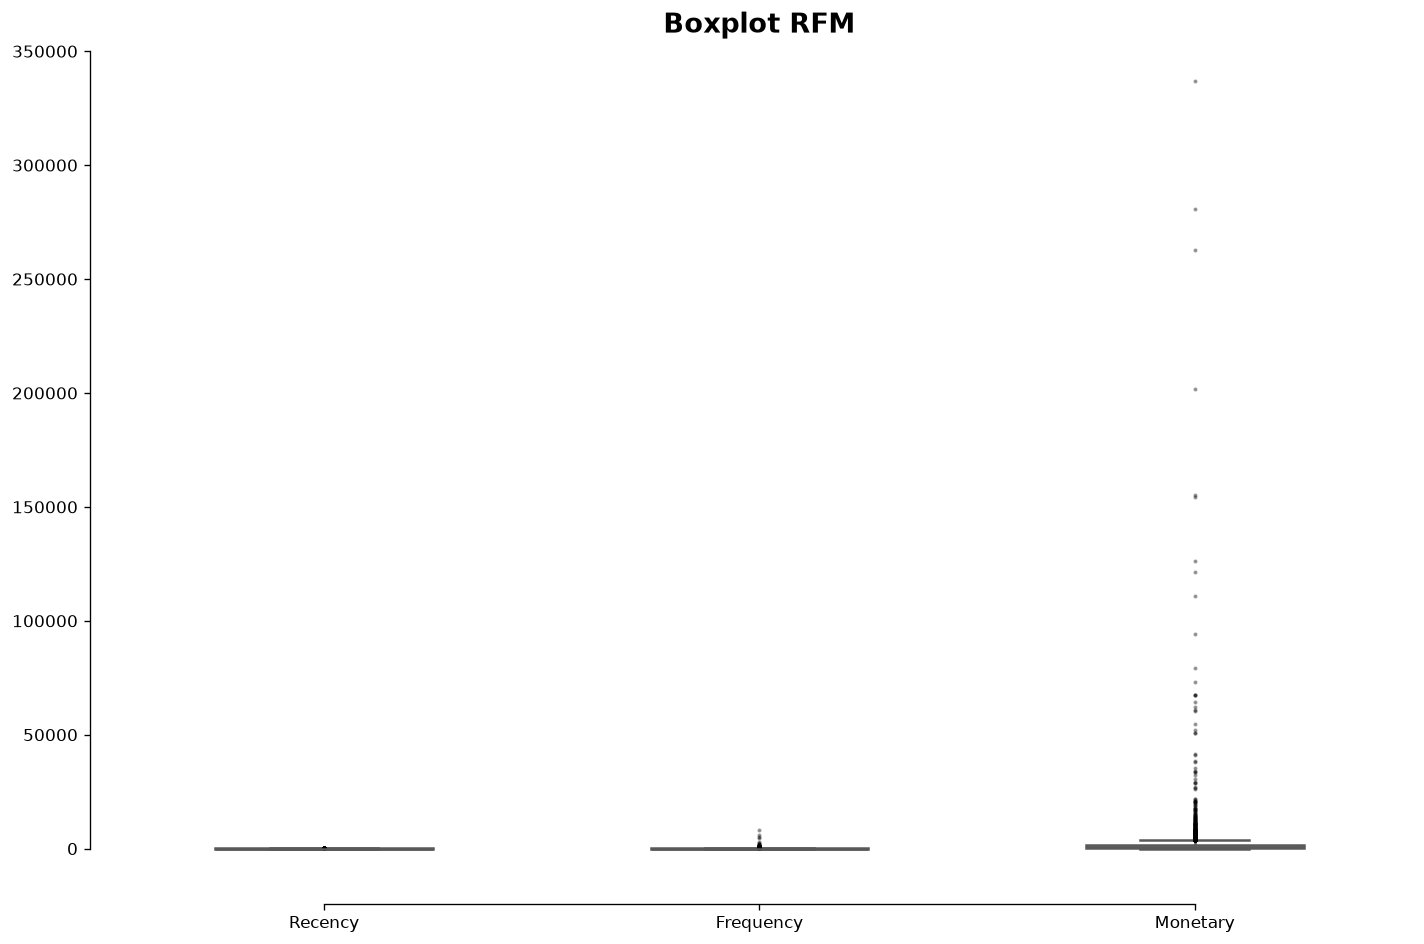

In [8]:
cols = ['Recency', 'Frequency', 'Monetary']
plt.figure(figsize=(12, 8))
ax = sns.boxplot(
    data=rfm[cols], palette=sns.color_palette("Set2", 3),
    width=0.5, linewidth=1.5,
    flierprops=dict(
        marker='.', markersize=3, alpha=0.3,
        markerfacecolor='black', markeredgecolor='black'
    )
)
ax.set_title("Boxplot RFM", fontsize=16, weight="bold")
sns.despine(offset=10, trim=True)
plt.tight_layout()
plt.show()

In [9]:
def handle_outlier(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    iqr = Q3 - Q1
    lower_bound = Q1 - 1.5 * iqr
    upper_bound = Q3 + 1.5 * iqr

    condition = (data[col] < lower_bound) | (data[col] > upper_bound)
    outlier = data[condition]
    print('Amount of Outlier:')
    print(outlier[col].count())

    no_outlier = data[~condition]

    return no_outlier.reset_index(drop=True)

for col in ['Recency', 'Frequency', 'Monetary']:
    rfm = handle_outlier(rfm, col)

Amount of Outlier:
149
Amount of Outlier:
373
Amount of Outlier:
313


## Feature Scaling & Dimensionality Reduction

Pada tahap ini, dilakukan proses standardisasi data menggunakan metode StandardScaler untuk menyamakan skala antarfitur sehingga setiap fitur memiliki kontribusi yang seimbang dalam proses clustering. Standardisasi dilakukan dengan mengubah nilai setiap fitur agar memiliki rata-rata (mean) sebesar 0 dan standar deviasi sebesar 1. Dengan demikian, perbedaan rentang nilai antarfitur RFM dapat diminimalkan sehingga tidak ada fitur yang mendominasi proses pengelompokan akibat perbedaan skala data.

In [10]:
cluster_cols = ['Recency', 'Frequency', 'Monetary']
X = rfm[cluster_cols].copy()

preprocessor = Pipeline(
    [
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=2, random_state=42))
    ]
)

X_scaled = pd.DataFrame(preprocessor.fit_transform(X), columns=['PCA_1', 'PCA_2'])

In [11]:
X_som = X_scaled.to_numpy()

# Tahap 2: Implementasi Self-Organizing Map (SOM)

## Konfigurasi SOM dan alasan pemilihan parameter

**Implementasi.** SOM dibangun sendiri menggunakan NumPy (kelas `SOM` pada sel di bawah), tanpa pustaka SOM siap pakai seperti MiniSom. Fungsi utamanya adalah `SOM.fit(X)` untuk pelatihan *online* dan `SOM.pemenang(X)` untuk mencari *Best Matching Unit* (BMU) setiap observasi. Pustaka pendukung: pandas, NumPy, scikit-learn (`StandardScaler`, `PCA`, `KMeans`, `silhouette_score`, `davies_bouldin_score`), Matplotlib, dan seaborn.

**Data masukan.** SOM dilatih pada `X_som`, yaitu fitur RFM yang telah distandardisasi (z-score) lalu diproyeksikan ke 2 komponen utama PCA (mempertahankan ±88,2% varians). Jadi tiap pelanggan adalah vektor 2 dimensi.

**Aturan pembaruan bobot.** Untuk setiap sampel $x(t)$ yang dipilih acak, BMU $c$ adalah neuron dengan $\lVert x(t)-w_c\rVert$ terkecil. Semua neuron kemudian digeser ke arah $x(t)$:

$$w_{ij}(t+1) = w_{ij}(t) + \alpha(t)\, h_{ij,c}(t)\,\big[x(t) - w_{ij}(t)\big], \qquad h_{ij,c}(t)=\exp\!\Big(-\tfrac{d_{ij,c}^2}{2\sigma(t)^2}\Big)$$

dengan $d_{ij,c}$ jarak neuron $(i,j)$ ke BMU pada grid, $\alpha(t)$ laju pembelajaran, dan $\sigma(t)$ lebar tetangga. Neuron yang dekat BMU digeser paling kuat, sehingga neuron bertetangga pada grid akhirnya mewakili data yang mirip.

| Parameter | Nilai | Alasan pemilihan |
|---|---|---|
| Ukuran grid | 20 × 20 (400 neuron) | Dengan N = 3.537 pelanggan, rata-rata ±8,8 pelanggan per neuron: cukup rinci untuk menangkap bentuk sebaran, tetapi tiap neuron masih mewakili beberapa pelanggan. Sejalan dengan aturan praktis jumlah neuron ≈ 5√N (≈ 297). Pengaruh ukuran grid diuji di Eksperimen 1. |
| Epoch | 20 (= 70.740 iterasi) | Satu iterasi memakai satu sampel acak; 20 epoch cukup agar bobot stabil (hasil antar-seed hampir sama, lihat Eksperimen 1). |
| Laju pembelajaran awal α₀ | 0,5, turun linear ke 0 | Besar di awal agar peta cepat tersusun, kecil di akhir agar bobot menetap. |
| σ awal | max(baris, kolom)/2 = 10, turun linear (batas bawah 0,5) | σ besar membuat seluruh peta tersusun secara global di awal; σ kecil di akhir menyetel detail lokal. |
| Fungsi tetangga | Gaussian | Pengaruh menurun halus terhadap jarak pada grid. |
| Inisialisasi bobot | Acak seragam pada rentang min–maks tiap fitur | Bobot awal berada di dalam wilayah data. |
| Seed | 1 | Hasil dapat direproduksi. |


In [12]:
class SOM:
    def __init__(self, baris=20, kolom=20, lr=0.5, sigma=None, epochs=20, seed=1):
        self.baris = baris
        self.kolom = kolom
        self.lr = lr
        self.sigma = sigma
        self.epochs = epochs
        self.seed = seed

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        jumlah_data, jumlah_fitur = X.shape
        self.bobot = rng.uniform(X.min(axis=0), X.max(axis=0), (self.baris, self.kolom, jumlah_fitur))
        if self.sigma is None:
            self.sigma = max(self.baris, self.kolom) / 2
        grid = np.array([(posisi_baris, posisi_kolom)
                         for posisi_baris in range(self.baris)
                         for posisi_kolom in range(self.kolom)])
        total = self.epochs * jumlah_data
        for langkah in range(total):
            x = X[rng.integers(jumlah_data)]
            progres = langkah / max(total -1, 1)
            learning_rate = self.lr * (1 - progres)
            sigma = max(0.5, self.sigma * (1 -progres))
            jarak = np.linalg.norm(self.bobot - x, axis=2)
            koordinat_neuron = np.unravel_index(np.argmin(jarak), jarak.shape)
            koordinat_neuron_array = np.array(koordinat_neuron)
            jarak_grid = np.sum((grid - koordinat_neuron_array) ** 2, axis=1)
            nilai_tetangga = np.exp(-jarak_grid / (2 * sigma ** 2)).reshape(self.baris, self.kolom, 1)
            self.bobot += (learning_rate * nilai_tetangga * (x - self.bobot))
        return self
    
    def pemenang(self, X):
        jarak = np.linalg.norm(X[:, None, None, :] - self.bobot[None, :, :, :], axis=3)
        return np.array([np.unravel_index(posisi, jarak.shape[1:])
                         for posisi in jarak.reshape(len(X), -1).argmin(axis=1)])

In [13]:
som = SOM(baris=20, kolom=20, lr=0.5, sigma=None, epochs=20, seed=1)
som.fit(X_som)
hasil_pemenang = som.pemenang(X_som)

In [14]:
hasil_pemenang.shape

(3537, 2)

In [15]:
hasil_pemenang[:10]

array([[13,  7],
       [18,  9],
       [ 3,  0],
       [ 0,  6],
       [ 9,  1],
       [ 4,  5],
       [17,  4],
       [15, 19],
       [17,  1],
       [ 1,  2]])

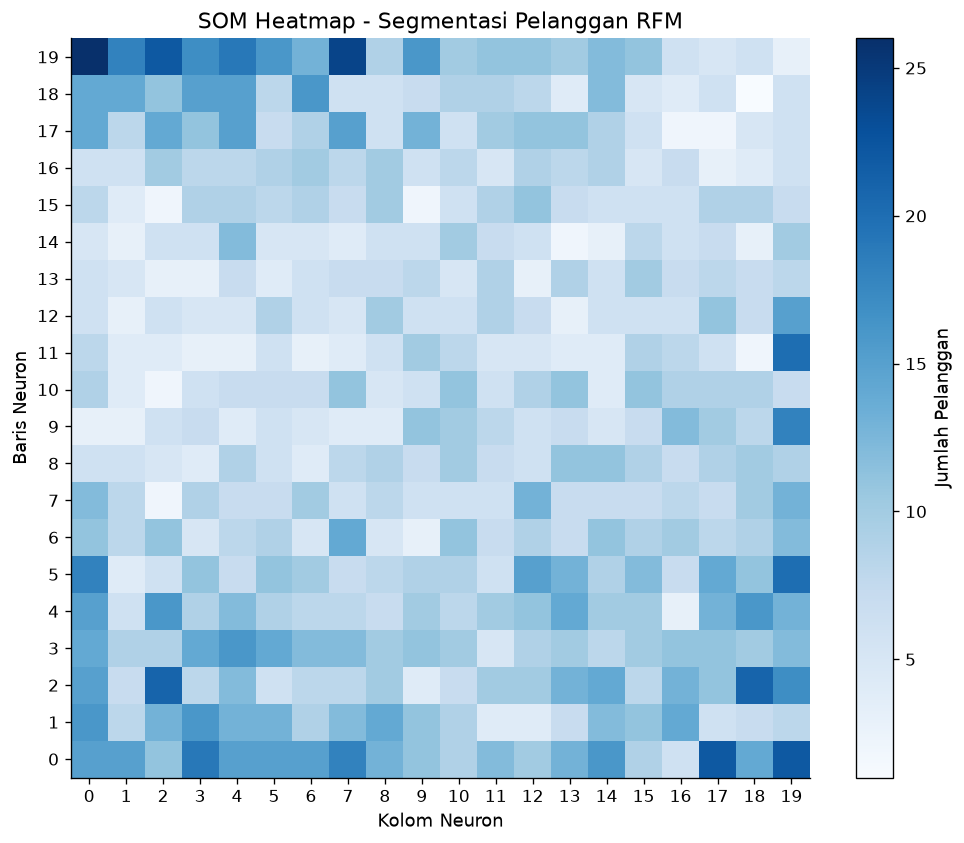

In [16]:
jumlah_pelanggan = np.zeros((som.baris, som.kolom), dtype=int)
for baris, kolom in hasil_pemenang:
    jumlah_pelanggan[baris, kolom] += 1

plt.figure(figsize=(10, 8))
plt.imshow(jumlah_pelanggan, cmap='Blues', origin='lower', interpolation='nearest')
plt.colorbar(label='Jumlah Pelanggan')
plt.title('SOM Heatmap - Segmentasi Pelanggan RFM')
plt.xlabel('Kolom Neuron')
plt.ylabel('Baris Neuron')
plt.xticks(range(som.kolom))
plt.yticks(range(som.baris))
plt.show()

In [17]:
hasil_rfm = X.copy().reset_index(drop=True)
hasil_rfm['baris_bmu'] = hasil_pemenang[:, 0]
hasil_rfm['kolom_bmu'] = hasil_pemenang[:, 1]

In [18]:
karakteristik_neuron = hasil_rfm.groupby(["baris_bmu", "kolom_bmu"]).agg(
    jumlah_pelanggan=("Recency", "size"),
    rata_recency=("Recency", "mean"),
    rata_frequency=("Frequency", "mean"),
    rata_monetary=("Monetary", "mean")).reset_index()
karakteristik_neuron.head(10)

,baris_bmu,kolom_bmu,jumlah_pelanggan,rata_recency,rata_frequency,rata_monetary
0,0,0,15,317.266667,3.933333,87.730000
1,0,1,15,293.933333,3.333333,71.266667
2,0,2,11,277.363636,4.454545,120.581818
3,0,3,19,258.894737,3.736842,74.342105
4,0,4,15,238.133333,6.400000,118.728000
5,0,5,15,217.733333,5.133333,113.964667
6,0,6,15,200.666667,5.200000,142.944000
7,0,7,18,183.444444,5.388889,96.278333
8,0,8,13,162.461538,5.923077,100.698462
9,0,9,11,139.545455,3.818182,120.610909


In [19]:
u_matrix = np.zeros((som.baris, som.kolom))

for baris in range(som.baris):
    for kolom in range(som.kolom):
        tetangga = []

        for i in range(-1, 2):
            for j in range(-1, 2):
                if i == 0 and j == 0:
                    continue

                b = baris + i
                k = kolom + j

                if 0 <= b < som.baris and 0 <= k < som.kolom:
                    jarak = np.linalg.norm(som.bobot[baris, kolom] - som.bobot[b, k])
                    tetangga.append(jarak)

        u_matrix[baris, kolom] = np.mean(tetangga)

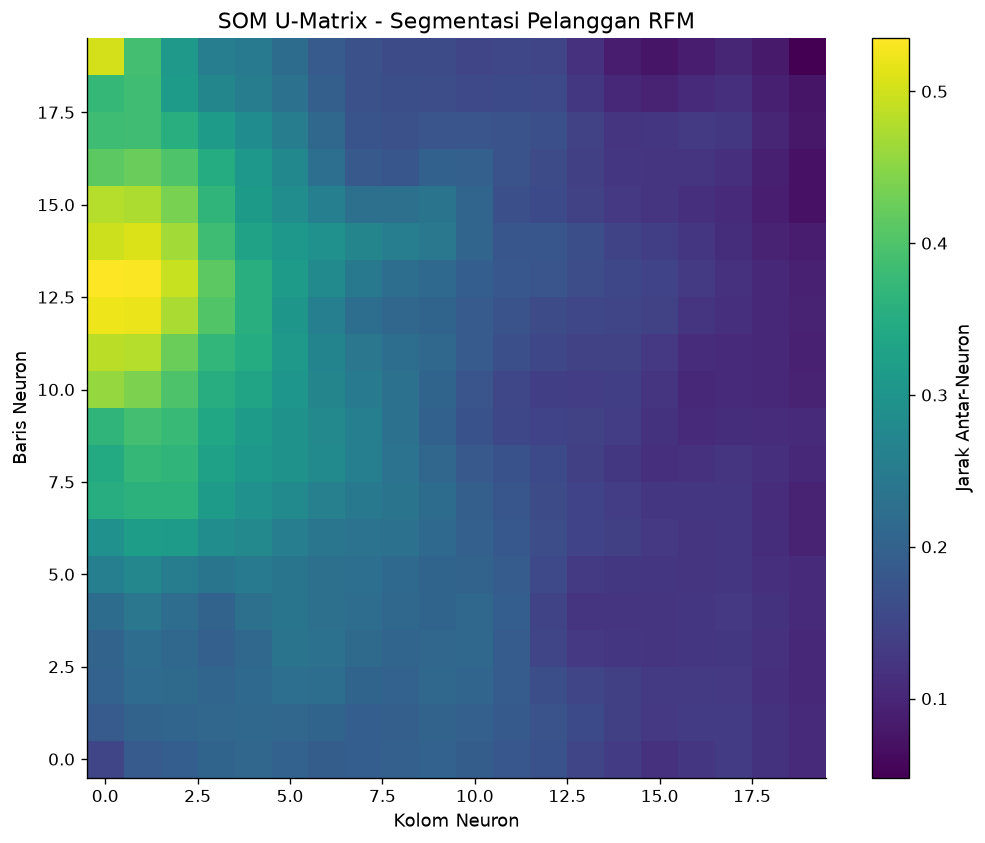

In [20]:
plt.figure(figsize=(10, 8))
plt.imshow(u_matrix, cmap='viridis', origin='lower', interpolation='nearest')
plt.colorbar(label='Jarak Antar-Neuron')
plt.title('SOM U-Matrix - Segmentasi Pelanggan RFM')
plt.xlabel('Kolom Neuron')
plt.ylabel('Baris Neuron')
plt.show()

In [21]:
print("Jarak minimum:", u_matrix.min())
print("Jarak maksimum:", u_matrix.max())
print("Rata-rata jarak:", u_matrix.mean())

Jarak minimum: 0.04796608268765016
Jarak maksimum: 0.5348859642884258
Rata-rata jarak: 0.20732057081798572


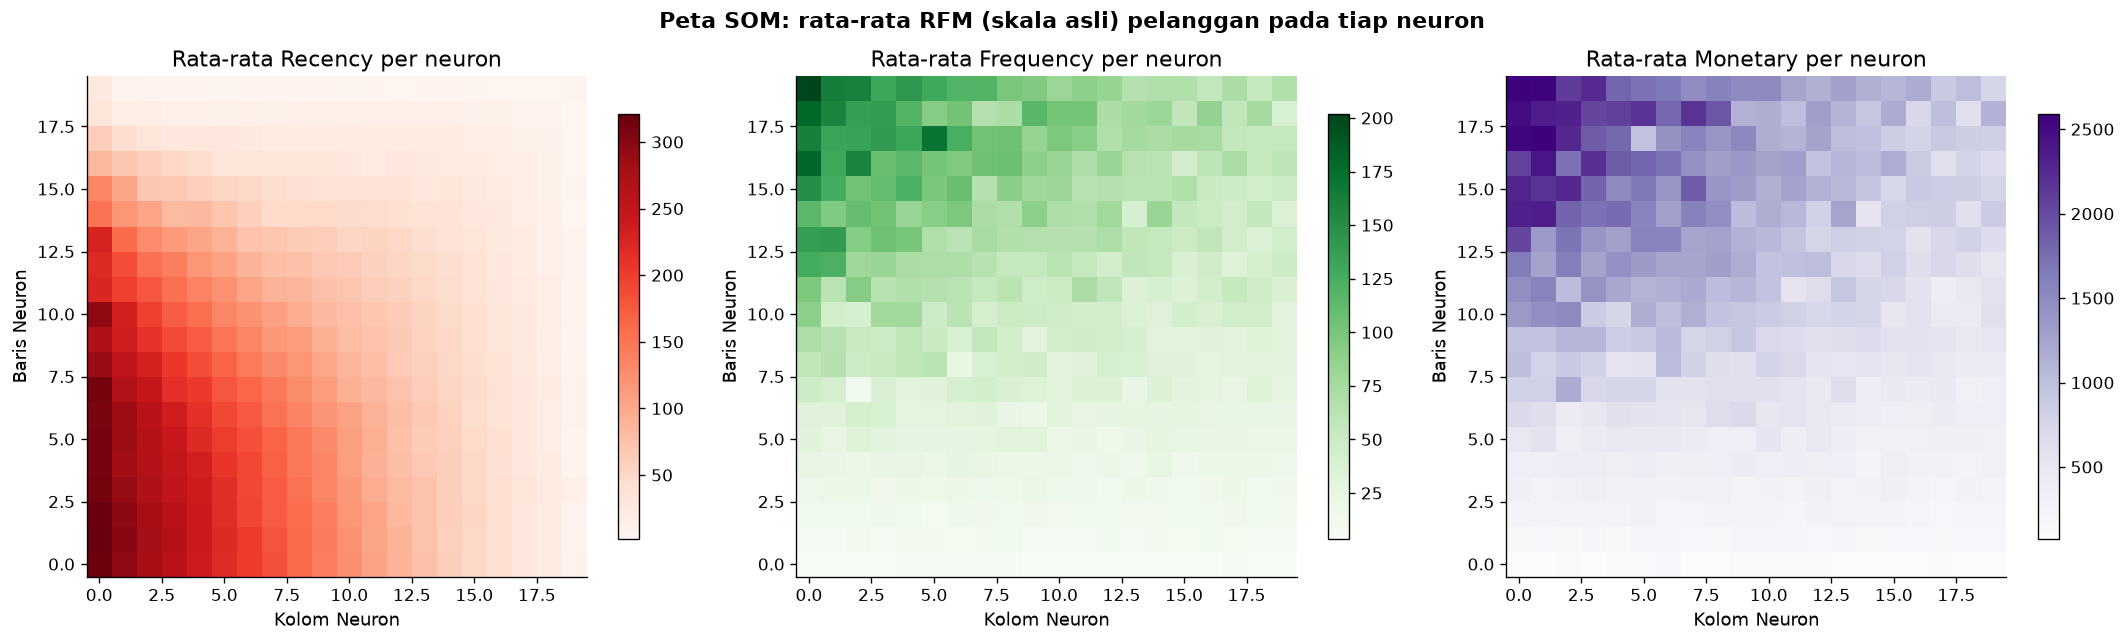

Neuron kosong          : 0
Min / median / maks    : 1 / 8 / 26
Rata-rata per neuron   : 8.84


In [22]:
# Peta rata-rata RFM per neuron: membantu menafsirkan arti posisi pada peta SOM
rata_rfm = {k: np.full((som.baris, som.kolom), np.nan) for k in ['Recency', 'Frequency', 'Monetary']}
for _, r in karakteristik_neuron.iterrows():
    b, k = int(r['baris_bmu']), int(r['kolom_bmu'])
    rata_rfm['Recency'][b, k] = r['rata_recency']
    rata_rfm['Frequency'][b, k] = r['rata_frequency']
    rata_rfm['Monetary'][b, k] = r['rata_monetary']

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for a, (nama, cmap) in zip(ax, [('Recency', 'Reds'), ('Frequency', 'Greens'), ('Monetary', 'Purples')]):
    im = a.imshow(rata_rfm[nama], cmap=cmap, origin='lower', interpolation='nearest')
    plt.colorbar(im, ax=a, shrink=0.8)
    a.set_title(f'Rata-rata {nama} per neuron')
    a.set_xlabel('Kolom Neuron')
    a.set_ylabel('Baris Neuron')
fig.suptitle('Peta SOM: rata-rata RFM (skala asli) pelanggan pada tiap neuron', fontweight='bold')
plt.tight_layout()
plt.show()

# Statistik jumlah pelanggan per neuron
print('Neuron kosong          :', int((jumlah_pelanggan == 0).sum()))
print('Min / median / maks    :', jumlah_pelanggan.min(), '/', int(np.median(jumlah_pelanggan)), '/', jumlah_pelanggan.max())
print('Rata-rata per neuron   : %.2f' % jumlah_pelanggan.mean())

### Interpretasi peta SOM dan BMU

**BMU.** Setiap pelanggan dipetakan ke neuron yang vektor bobotnya paling dekat (jarak Euclidean) dengan vektor fitur pelanggan tersebut. Neuron itulah BMU, dan posisinya `(baris_bmu, kolom_bmu)` disimpan pada `hasil_pemenang`. Pelanggan yang BMU-nya sama atau bertetangga memiliki pola RFM yang mirip.

**Hitungan data per neuron.** Seluruh 400 neuron terpakai (tidak ada neuron kosong). Jumlah pelanggan per neuron berkisar 1–26 (median 8, rata-rata 8,84). Neuron di tepi dan sudut peta cenderung menampung lebih banyak pelanggan, karena neuron tepi menyerap titik-titik di ujung sebaran data.

**U-Matrix.** Jarak rata-rata antar-neuron bertetangga berkisar 0,048–0,535 (rata-rata 0,207). Jarak terbesar terkonsentrasi di tepi kiri peta (kolom 0–3, baris ±10–16): bobot neuron di sana saling berjauhan karena peta meregang untuk menjangkau wilayah ruang fitur yang jarang diisi data, yaitu pelanggan dengan nilai belanja dan frekuensi sangat tinggi. Jarak kecil di sisi kanan menandakan wilayah padat berisi pelanggan tipikal. Tidak tampak "tembok" tajam yang memisahkan peta menjadi pulau-pulau terpisah. Perubahan jarak bersifat bertahap, sehingga data RFM lebih menyerupai kontinum daripada kelompok yang terpisah jelas.

**Peta rata-rata RFM per neuron.** Peta ini menunjukkan bahwa posisi pada grid bermakna. *Recency* tinggi (pelanggan lama tidak bertransaksi, hingga ±320 hari) terkumpul di sisi kiri-bawah. *Frequency* dan *Monetary* naik ke arah atas dan mencapai nilai tertinggi di kiri-atas (sekitar 200 transaksi dan di atas £2.500). Sisi kanan-bawah berisi pelanggan yang baru bertransaksi tetapi dengan frekuensi dan nilai belanja rendah. Dengan demikian SOM menyusun pelanggan secara teratur: kedekatan pada peta mencerminkan kemiripan perilaku RFM.


# Tahap 3: Clustering menggunakan SOM + K-Means

## Ambil Vector Bobot

In [23]:
neuron_criteria = np.unique(hasil_pemenang, axis=0)
prototipe = np.array([som.bobot[baris, kolom] for baris, kolom in neuron_criteria])

print('Jumlah neuron terpakai:', len(neuron_criteria))
print('Jumlah prototipe:', len(prototipe))
print('Dimensi prototipe:', prototipe.shape)

Jumlah neuron terpakai: 400
Jumlah prototipe: 400
Dimensi prototipe: (400, 2)


## Penerapan Bobot pada KMeans

K Optimization: 100%|██████████| 10/10 [00:00<00:00, 49.23it/s]


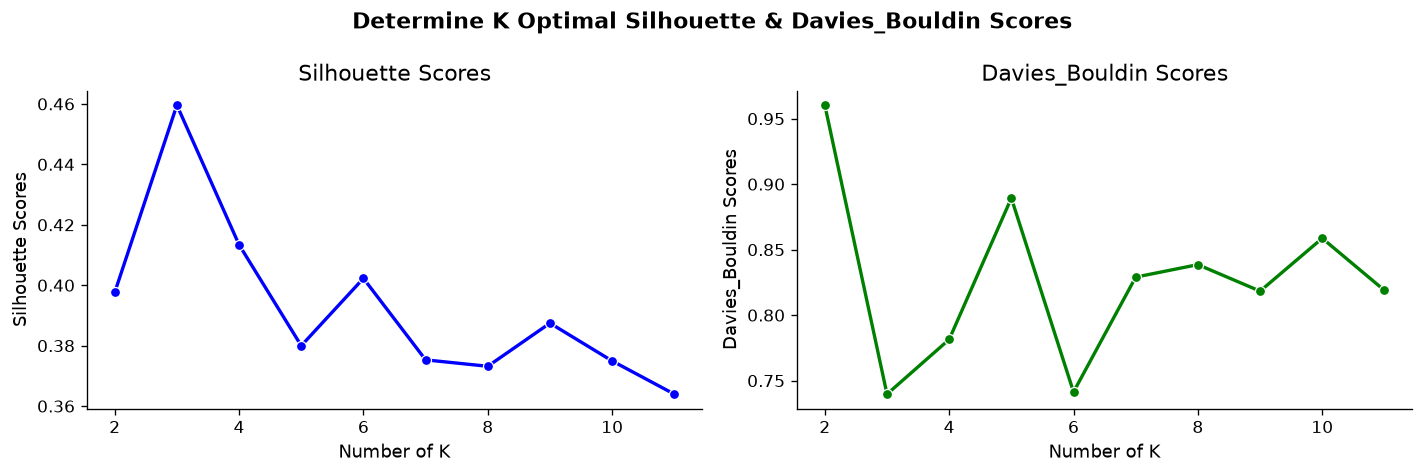

In [24]:
k_range = range(2, 12)
silhouette, db_scores = [], []
for i in tqdm(k_range, desc='K Optimization'):
    model = KMeans(n_clusters=i, random_state=CFG.SEED)
    label = model.fit_predict(prototipe)
    silhouette.append(silhouette_score(prototipe, label))
    db_scores.append(davies_bouldin_score(prototipe, label))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Determine K Optimal Silhouette & Davies_Bouldin Scores', fontweight='bold')
for i, eval in enumerate([silhouette, db_scores]):
    color = 'blue' if eval == silhouette else 'green'
    title = 'Silhouette Scores' if eval == silhouette else 'Davies_Bouldin Scores'
    sns.lineplot(x=list(k_range), y=eval, color=color, marker='o', linewidth=2, markersize=6, ax=ax[i])
    ax[i].set_title(title)
    ax[i].set_xlabel('Number of K')
    ax[i].set_ylabel(title)
plt.tight_layout()
plt.show()

## Label Seluruh Data Observasi berdasarkan BMU

In [25]:
model = KMeans(n_clusters=3, random_state=CFG.SEED)
label = model.fit_predict(prototipe)

mapping_label = {tuple(posisi): label for posisi, label in zip(neuron_criteria, label)}
hasil_pemenang_cluster = np.array([mapping_label[tuple(posisi)] for posisi in hasil_pemenang])

print("Jumlah prototipe:", len(prototipe))
print("Label cluster data:", hasil_pemenang_cluster)
print('Jumlah Akhir Label:', len(hasil_pemenang_cluster))

Jumlah prototipe: 400
Label cluster data: [1 1 2 ... 2 0 1]
Jumlah Akhir Label: 3537


## Visualisasi Hasil Cluster pada Peta SOM & Penjelasan Karakteristik

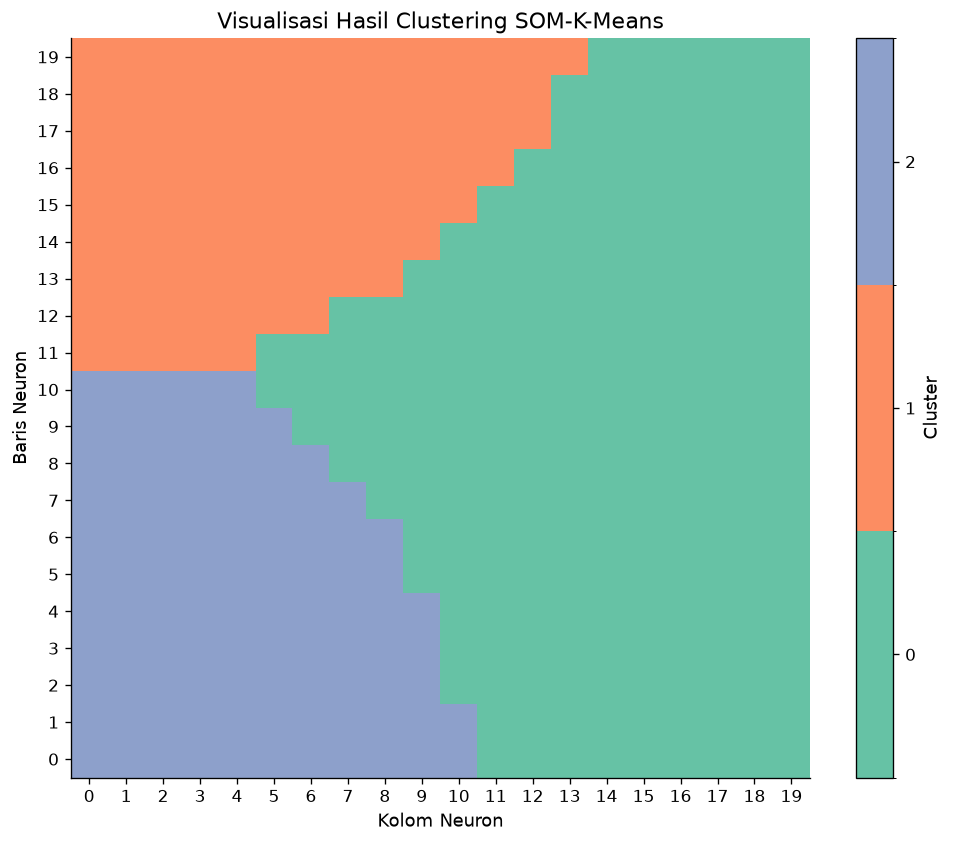

In [26]:
mapping_cluster_res_3 = np.full((som.baris, som.kolom), np.nan)
for posisi, cluster in zip(neuron_criteria, label):
    baris, kolom = posisi
    mapping_cluster_res_3[baris, kolom] = cluster

jumlah_cluster = len(np.unique(label))
warna = sns.color_palette('Set2', jumlah_cluster)
cmap = ListedColormap(warna)
batas = np.arange(-0.5, jumlah_cluster + 0.5, 1)
norm = BoundaryNorm(batas, cmap.N)

plt.figure(figsize=(10, 8))
plt.imshow(mapping_cluster_res_3, cmap=cmap, norm=norm, interpolation='nearest', aspect='equal', origin='lower')
plt.colorbar(ticks=np.arange(jumlah_cluster), label='Cluster')

plt.title('Visualisasi Hasil Clustering SOM-K-Means')
plt.xlabel('Kolom Neuron')
plt.ylabel('Baris Neuron')
plt.xticks(range(som.kolom))
plt.yticks(range(som.baris))
plt.show()

Peta cluster di atas digambar dengan `origin='lower'` agar orientasinya sama dengan heatmap jumlah pelanggan, U-Matrix, dan peta RFM (baris 0 di bawah). Hasil SOM + K-Means (K = 3) menunjukkan tiga wilayah yang masing-masing bersambung (kontigu) pada peta 20 × 20:

- **Cluster 0 (hijau)** menempati seluruh sisi kanan peta dan membentang dari baris 0 sampai 19. Ini wilayah terluas (±210 neuron, 1.776 pelanggan atau 50,2%).
- **Cluster 1 (oranye)** berada di kiri-atas (baris 11–19, kolom 0–13; ±94 neuron, 835 pelanggan atau 23,6%).
- **Cluster 2 (biru)** berada di kiri-bawah (baris 0–10, kolom 0–10; ±96 neuron, 926 pelanggan atau 26,2%).

Wilayah cluster yang bersambung menunjukkan bahwa topologi peta terjaga: neuron bertetangga cenderung mendapat label yang sama. Batas cluster 1 dan 2 hampir mendatar di sekitar baris 10–11, sejalan dengan gradien *Frequency* dan *Monetary* yang naik ke atas. Batas keduanya dengan cluster 0 berbentuk diagonal. Nomor cluster bersifat arbitrer (hanya penanda), sehingga arti tiap cluster dibaca dari profil RFM-nya pada sel berikut.


### Makna cluster SOM + K-Means: profil RFM

In [27]:
# Profil RFM setiap cluster hasil SOM + K-Means (skala asli)
hasil_som_km = X.copy().reset_index(drop=True)
hasil_som_km['cluster_som_kmeans'] = hasil_pemenang_cluster

karakteristik_som_km = hasil_som_km.groupby('cluster_som_kmeans').agg(
    jumlah_pelanggan=('Recency', 'size'),
    rata_recency=('Recency', 'mean'),
    rata_frequency=('Frequency', 'mean'),
    rata_monetary=('Monetary', 'mean')).reset_index()
karakteristik_som_km['persentase(%)'] = karakteristik_som_km['jumlah_pelanggan'] / len(hasil_som_km) * 100
display(karakteristik_som_km.round(2))

# Nama segmen diturunkan dari profil RFM (bukan ditulis manual) agar konsisten bila hasil berubah
def nama_segmen(profil, kolom_cluster):
    tinggi = profil.loc[profil['rata_monetary'].idxmax(), kolom_cluster]
    pasif = profil.loc[profil['rata_recency'].idxmax(), kolom_cluster]
    return {c: ('Bernilai Tinggi' if c == tinggi else 'Tidak Aktif' if c == pasif else 'Aktif Menengah')
            for c in profil[kolom_cluster]}

segmen_som = nama_segmen(karakteristik_som_km, 'cluster_som_kmeans')
print(segmen_som)

,cluster_som_kmeans,jumlah_pelanggan,rata_recency,rata_frequency,rata_monetary,persentase(%)
0,0,1776,45.84,34.01,560.11,50.21
1,1,835,42.93,113.78,1731.29,23.61
2,2,926,225.33,22.52,382.35,26.18


{0: 'Aktif Menengah', 1: 'Bernilai Tinggi', 2: 'Tidak Aktif'}


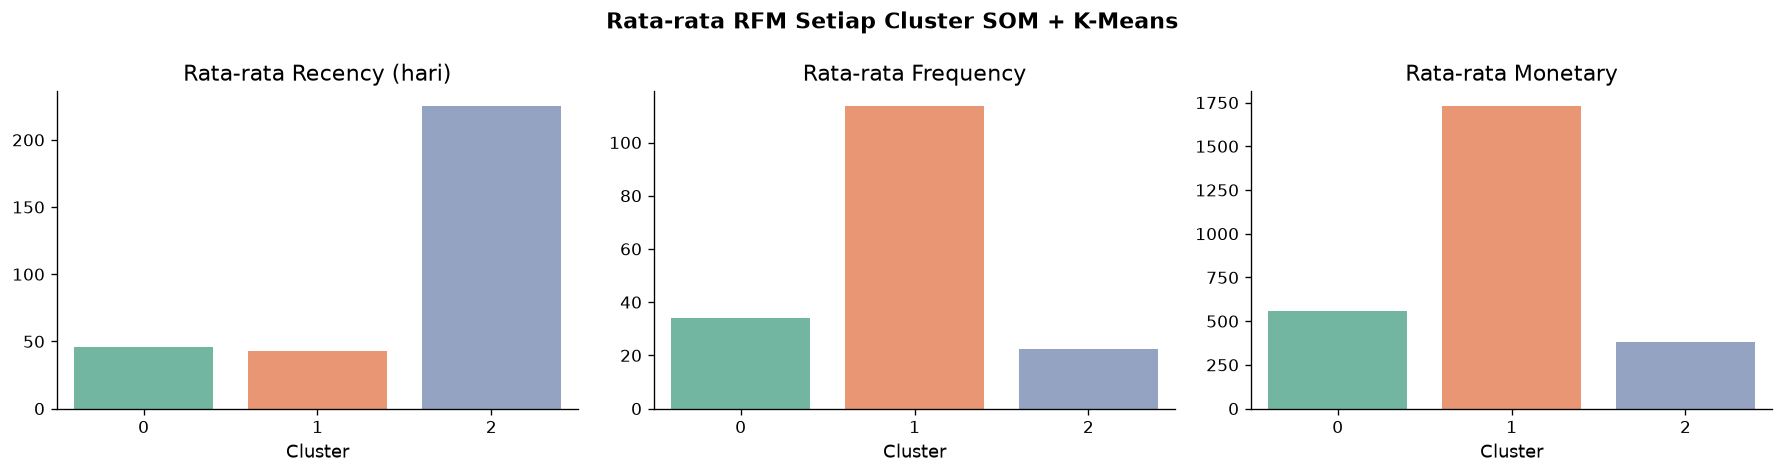

In [28]:
# Bar chart rata-rata RFM tiap cluster SOM + K-Means
warna3 = sns.color_palette('Set2', 3)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Rata-rata RFM Setiap Cluster SOM + K-Means', fontweight='bold')
for i, (kolom, judul) in enumerate([('rata_recency', 'Rata-rata Recency (hari)'),
                                    ('rata_frequency', 'Rata-rata Frequency'),
                                    ('rata_monetary', 'Rata-rata Monetary')]):
    sns.barplot(data=karakteristik_som_km, x='cluster_som_kmeans', y=kolom,
                hue='cluster_som_kmeans', palette=warna3, legend=False, ax=ax[i])
    ax[i].set_title(judul)
    ax[i].set_xlabel('Cluster')
    ax[i].set_ylabel('')
plt.tight_layout()
plt.show()

Profil RFM (skala asli) tiap cluster hasil SOM + K-Means:

| Cluster | Segmen | Jumlah (%) | Recency (hari) | Frequency | Monetary (£) |
|---|---|---|---|---|---|
| 0 | Aktif Menengah | 1.776 (50,2%) | 45,8 | 34,0 | 560 |
| 1 | Bernilai Tinggi | 835 (23,6%) | 42,9 | 113,8 | 1.731 |
| 2 | Tidak Aktif | 926 (26,2%) | 225,3 | 22,5 | 382 |

- **Aktif Menengah** baru bertransaksi (±46 hari) dengan frekuensi dan nilai belanja sedang. Mereka segmen terbesar dan cocok untuk program peningkatan frekuensi belanja.
- **Bernilai Tinggi** sama-sama aktif (±43 hari), tetapi frekuensinya sekitar tiga kali dan nilai belanjanya sekitar tiga kali segmen Aktif Menengah. Segmen ini perlu dijaga dengan program loyalitas atau layanan khusus.
- **Tidak Aktif** sudah ±225 hari tidak bertransaksi dengan frekuensi dan nilai belanja terendah. Mereka berisiko berhenti (*churn*) sehingga cocok untuk kampanye aktivasi ulang.

Catatan: *Frequency* dihitung sebagai jumlah baris transaksi (item faktur) per pelanggan, bukan jumlah faktur unik. Pelanggan "Bernilai Tinggi" bersifat relatif terhadap pelanggan yang tersisa setelah penanganan outlier (lihat bagian Keterbatasan).


# Tahap 4: Pembanding K-means pada data asli

### Penerapan K-Means secara langsung

#### Tujuan metode

Pada tahap ini, algoritma K-Means diterapkan secara langsung pada data pelanggan yang telah melalui proses standardisasi dan reduksi dimensi menggunakan PCA, tanpa menggunakan pemetaan neuron SOM terlebih dahulu. **Tujuannya adalah menghasilkan pengelompokan pelanggan sebagai pembanding terhadap metode SOM-K-Means pada Tahap 3**


Jumlah cluster ditetapkan sebanyak tiga (K=3), sama seperti metode SOM-K-Means, agar hasil kedua metode dapat dibandingkan dengan jumlah kelompok yang setara.

In [29]:
K = 3  # jumlah cluster sama dengan SOM + K-Means (Tahap 3)

kmeans_langsung = KMeans(n_clusters=K, random_state=CFG.SEED)
label_kmeans_langsung = kmeans_langsung.fit_predict(X_som)

ukuran_cluster = pd.Series(label_kmeans_langsung).value_counts().sort_index()

print('Jumlah observasi:', len(label_kmeans_langsung))
print('Jumlah cluster:', K)
print('Ukuran setiap cluster:')
print(ukuran_cluster)

Jumlah observasi: 3537
Jumlah cluster: 3
Ukuran setiap cluster:
0    1830
1     815
2     892
Name: count, dtype: int64


### Karakteristik cluster

In [30]:
hasil_kmeans = X.copy().reset_index(drop=True)
hasil_kmeans['cluster_kmeans'] = label_kmeans_langsung

karakteristik_kmeans = hasil_kmeans.groupby('cluster_kmeans').agg(
    jumlah_pelanggan=('Recency', 'size'),
    rata_recency=('Recency', 'mean'),
    rata_frequency=('Frequency', 'mean'),
    rata_monetary=('Monetary', 'mean')).reset_index()

karakteristik_kmeans['persentase(%)'] = karakteristik_kmeans['jumlah_pelanggan'] / len(hasil_kmeans) * 100
display(karakteristik_kmeans.round(2))

,cluster_kmeans,jumlah_pelanggan,rata_recency,rata_frequency,rata_monetary,persentase(%)
0,0,1830,47.82,33.97,562.07,51.74
1,1,815,41.52,114.93,1743.00,23.04
2,2,892,229.33,22.89,387.11,25.22


### Visualisasi scatter PCA

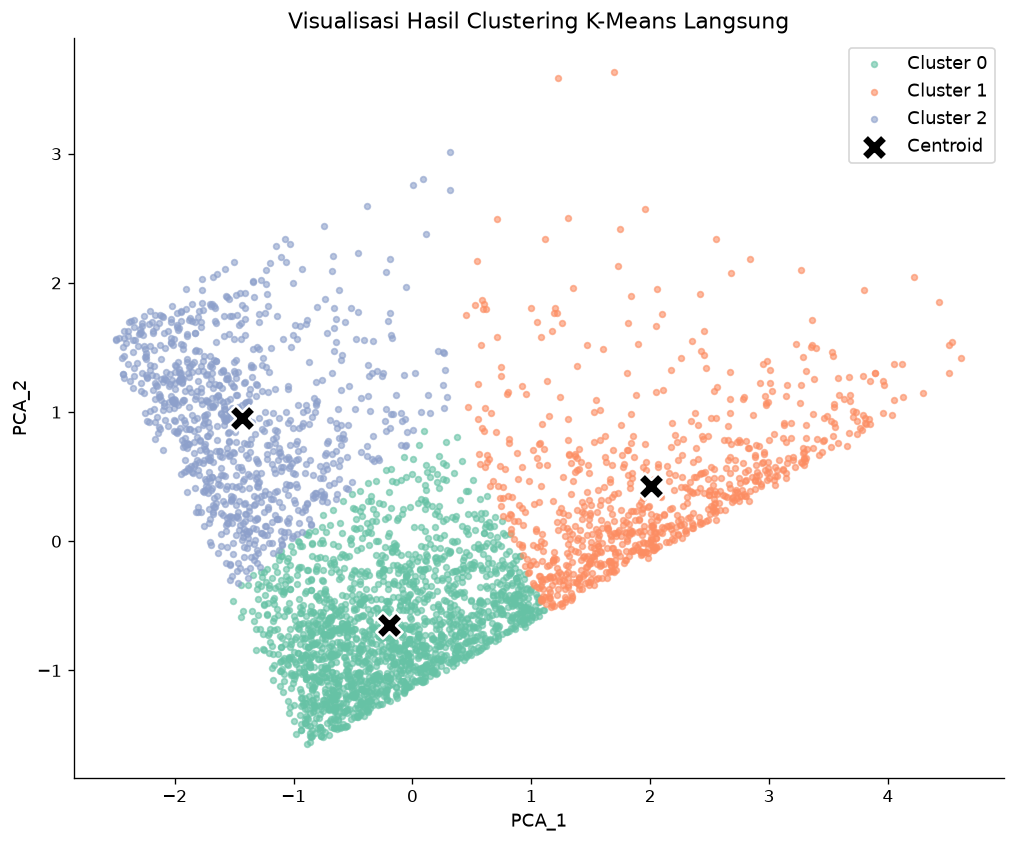

In [31]:
warna = sns.color_palette('Set2', K)
pusat_cluster = kmeans_langsung.cluster_centers_

plt.figure(figsize=(10, 8))
for cluster in range(K):
    anggota = label_kmeans_langsung == cluster
    plt.scatter(X_som[anggota, 0], X_som[anggota, 1], s=12, alpha=0.6,
                color=warna[cluster], label=f'Cluster {cluster}')
plt.scatter(pusat_cluster[:, 0], pusat_cluster[:, 1], marker='X', s=250,
            color='black', edgecolor='white', linewidth=1.5, label='Centroid')

plt.title('Visualisasi Hasil Clustering K-Means Langsung')
plt.xlabel('PCA_1')
plt.ylabel('PCA_2')
plt.legend()
plt.show()

### Bar chart rata - rata RFM

#### Tujuan Visualisasi

Visualisasi bar chart digunakan untuk membandingkan rata-rata nilai Recency, Frequency, dan Monetary pada setiap cluster. **Tujuannya adalah memperjelas perbedaan karakteristik perilaku pelanggan serta membantu mengidentifikasi kelompok pelanggan yang paling aktif, memiliki nilai transaksi tertinggi, dan kurang aktif.**

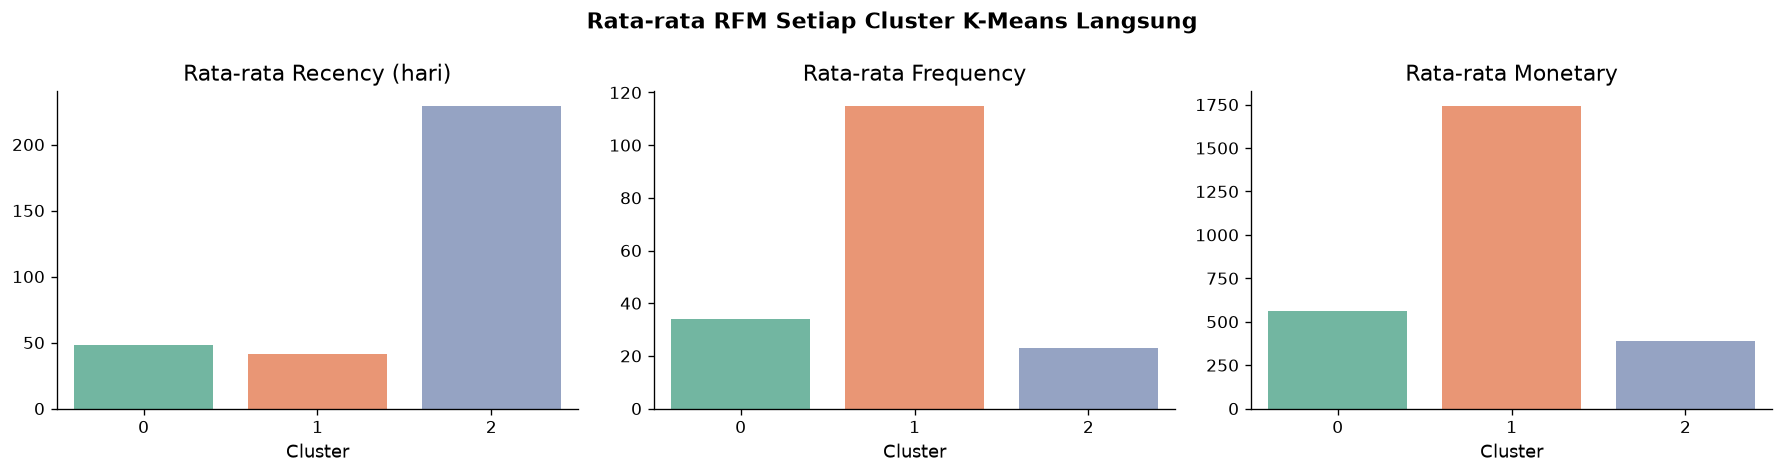

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Rata-rata RFM Setiap Cluster K-Means Langsung', fontweight='bold')

for i, (kolom, judul) in enumerate([('rata_recency', 'Rata-rata Recency (hari)'),
                                    ('rata_frequency', 'Rata-rata Frequency'),
                                    ('rata_monetary', 'Rata-rata Monetary')]):
    sns.barplot(data=karakteristik_kmeans, x='cluster_kmeans', y=kolom,
                hue='cluster_kmeans', palette=warna, legend=False, ax=ax[i])
    ax[i].set_title(judul)
    ax[i].set_xlabel('Cluster')
    ax[i].set_ylabel('')
plt.tight_layout()
plt.show()

### Kesimpulan

Berdasarkan hasil penerapan K-Means secara langsung, sebanyak 3.537 pelanggan berhasil dikelompokkan menjadi tiga cluster. Cluster 0 merupakan pelanggan dengan aktivitas transaksi menengah, Cluster 1 merupakan pelanggan bernilai tinggi dengan frekuensi dan nilai transaksi terbesar, sedangkan Cluster 2 merupakan pelanggan kurang aktif. Hasil ini digunakan sebagai pembanding metode SOM-K-Means pada Tahap 3 untuk mengevaluasi kualitas pengelompokan pelanggan

# Tahap 5: Evaluasi dan Diskusi

Kedua pendekatan dievaluasi dengan **Silhouette Score** (rentang −1 sampai 1, makin tinggi makin baik) dan **Davies–Bouldin Index/DBI** (≥ 0, makin rendah makin baik). Metrik dihitung pada data observasi hasil standardisasi yang menjadi masukan kedua algoritma (`X_som`, yaitu RFM terstandardisasi dan diproyeksikan PCA 2D), memakai label hasil masing-masing pendekatan. Sebagai pemeriksaan tambahan, metrik yang sama juga dihitung pada tiga fitur RFM terstandardisasi tanpa PCA (`X_std3`).

## 5.1 Tabel metrik evaluasi


In [33]:
from sklearn.metrics import silhouette_samples, adjusted_rand_score

# Data standardisasi 3 fitur RFM (tanpa PCA) sebagai pemeriksaan tambahan
X_std3 = StandardScaler().fit_transform(X)

def hitung_metrik(label):
    return {'Silhouette (PCA 2D)': silhouette_score(X_som, label),
            'DBI (PCA 2D)': davies_bouldin_score(X_som, label),
            'Silhouette (RFM std 3D)': silhouette_score(X_std3, label), 
            'DBI (RFM std 3D)': davies_bouldin_score(X_std3, label)}

tabel_metrik = pd.DataFrame({'SOM + K-Means': hitung_metrik(hasil_pemenang_cluster), 
                             'K-Means langsung': hitung_metrik(label_kmeans_langsung)}).T
tabel_metrik.loc['Selisih (SOM - KM)'] = tabel_metrik.loc['SOM + K-Means'] - tabel_metrik.loc['K-Means langsung']
display(tabel_metrik.round(4))

,Silhouette (PCA 2D),DBI (PCA 2D),Silhouette (RFM std 3D),DBI (RFM std 3D)
SOM + K-Means,0.4968,0.6793,0.4315,0.8307
K-Means langsung,0.5006,0.6739,0.4358,0.8240
Selisih (SOM - KM),-0.0037,0.0055,-0.0042,0.0067


**Pembahasan.** K-Means langsung sedikit lebih baik pada kedua metrik dan kedua ruang data: Silhouette 0,5006 berbanding 0,4968 (selisih 0,0037, ±0,7%) dan DBI 0,6739 berbanding 0,6793 pada ruang PCA 2D. Pola yang sama muncul pada ruang RFM 3D (Silhouette 0,4358 vs 0,4315; DBI 0,8240 vs 0,8307). Selisihnya sangat kecil, sehingga kedua pendekatan praktis setara dari sisi metrik. Hasil yang sedikit lebih baik pada K-Means langsung wajar, karena Silhouette dan DBI mengukur kekompakan dan keterpisahan di ruang fitur, yaitu geometri yang memang dioptimalkan K-Means langsung. Pada SOM + K-Means, label diberikan melalui 400 prototipe sehingga batas cluster terkena pembulatan oleh kisi neuron.

## 5.2 Ukuran cluster dan kesesuaian label


In [34]:
# Ukuran cluster kedua pendekatan (dengan nama segmen berdasarkan profil RFM masing-masing)
karakteristik_kmeans_seg = nama_segmen(karakteristik_kmeans, 'cluster_kmeans')

ukuran = pd.DataFrame({'Segmen': [segmen_som[c] for c in sorted(segmen_som)],
                       'SOM + K-Means (n)': [int((hasil_pemenang_cluster == c).sum()) for c in sorted(segmen_som)],
                       'K-Means langsung (n)': [int((label_kmeans_langsung == c).sum()) for c in sorted(karakteristik_kmeans_seg)]})
ukuran['SOM + K-Means (%)'] = ukuran['SOM + K-Means (n)'] / len(X) * 100
ukuran['K-Means langsung (%)'] = ukuran['K-Means langsung (n)'] / len(X) * 100
display(ukuran.round(2))

# Kesesuaian label antar dua pendekatan
ari = adjusted_rand_score(hasil_pemenang_cluster, label_kmeans_langsung)
print('Adjusted Rand Index (SOM+KM vs KM langsung): %.4f' % ari)
print('Proporsi observasi dengan label sama        : %.2f%%' % (np.mean(hasil_pemenang_cluster == label_kmeans_langsung) * 100))
print()
tab_silang = pd.crosstab(pd.Series(hasil_pemenang_cluster, name='SOM + K-Means'),
                         pd.Series(label_kmeans_langsung, name='K-Means langsung'))
display(tab_silang)

# Silhouette rata-rata per cluster
sil_som = silhouette_samples(X_som, hasil_pemenang_cluster)
sil_km = silhouette_samples(X_som, label_kmeans_langsung)
sil_per_cluster = pd.DataFrame({'Cluster': range(3),
                                'Silhouette SOM + K-Means': [sil_som[hasil_pemenang_cluster == c].mean() for c in range(3)],
                                'Silhouette K-Means langsung': [sil_km[label_kmeans_langsung == c].mean() for c in range(3)]})
display(sil_per_cluster.round(4))

,Segmen,SOM + K-Means (n),K-Means langsung (n),SOM + K-Means (%),K-Means langsung (%)
0,Aktif Menengah,1776,1830,50.21,51.74
1,Bernilai Tinggi,835,815,23.61,23.04
2,Tidak Aktif,926,892,26.18,25.22


Adjusted Rand Index (SOM+KM vs KM langsung): 0.9421
Proporsi observasi dengan label sama        : 98.11%



K-Means langsung,0,1,2
SOM + K-Means,,,
0,1773,3,0
1,16,812,7
2,41,0,885


,Cluster,Silhouette SOM + K-Means,Silhouette K-Means langsung
0,0,0.5232,0.5125
1,1,0.4514,0.4691
2,2,0.4873,0.5049


**Pembahasan.** Ukuran cluster kedua pendekatan hampir sama (Aktif Menengah 1.776 vs 1.830, Bernilai Tinggi 835 vs 815, Tidak Aktif 926 vs 892). Label kedua pendekatan sama untuk 98,11% pelanggan (ARI = 0,9421). Dari 67 pelanggan yang berbeda, 41 pelanggan yang oleh K-Means langsung dimasukkan ke Aktif Menengah dimasukkan SOM + K-Means ke Tidak Aktif. Ini pelanggan di perbatasan kedua segmen tersebut. Silhouette per cluster juga mirip: Aktif Menengah sedikit lebih tinggi pada SOM + K-Means (0,5232 vs 0,5125), sedangkan Bernilai Tinggi (0,4514 vs 0,4691) dan Tidak Aktif (0,4873 vs 0,5049) sedikit lebih rendah. Segmen Bernilai Tinggi paling kurang kompak pada kedua pendekatan karena sebarannya paling melebar.

## 5.3 Visualisasi perbandingan pada ruang fitur


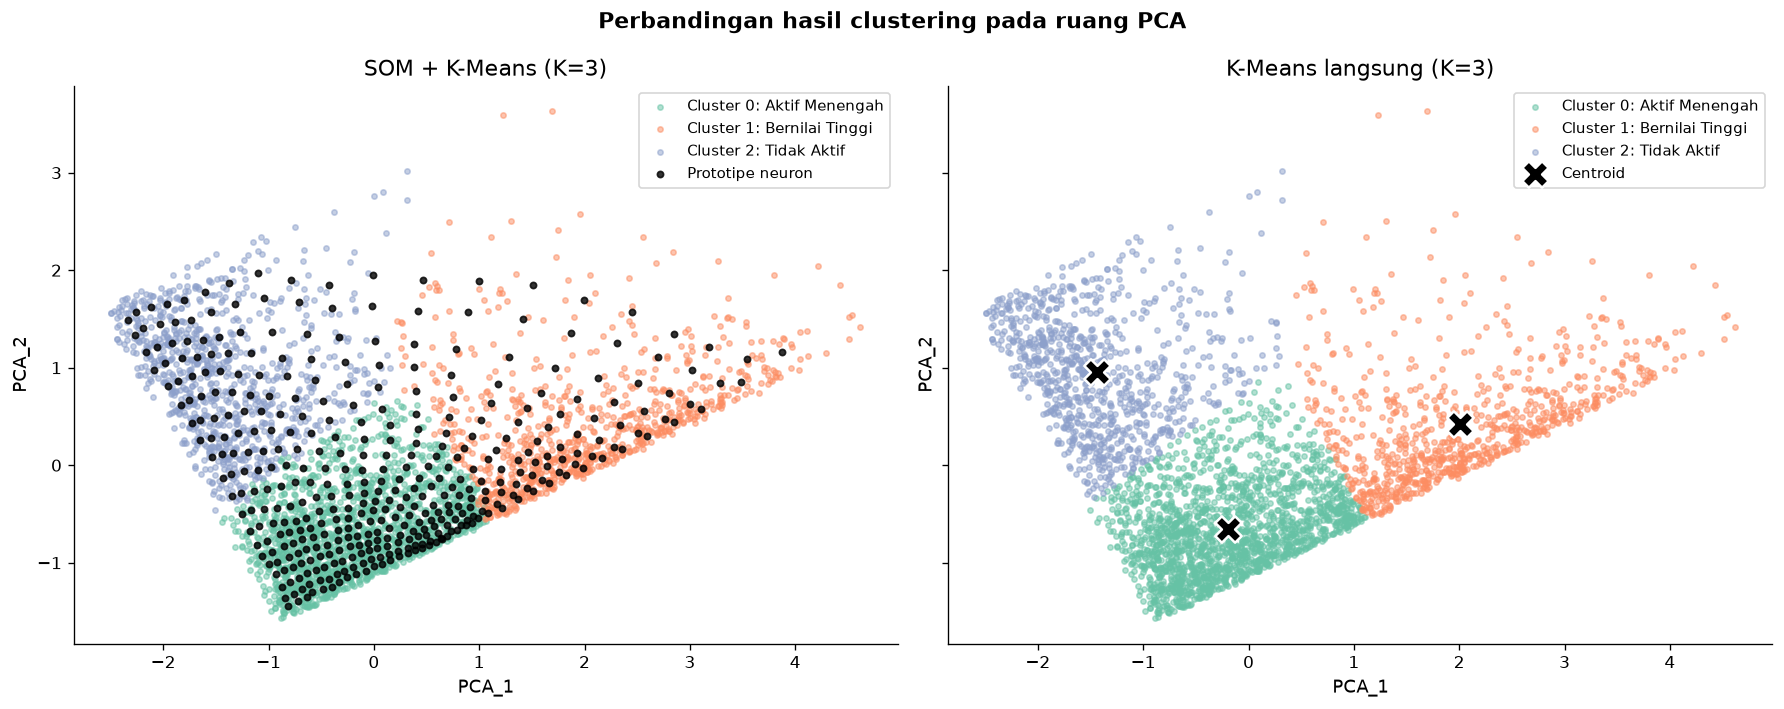

In [35]:
# Visualisasi berdampingan pada ruang fitur (PCA 2D)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for c in range(3):
    m = hasil_pemenang_cluster == c
    ax[0].scatter(X_som[m, 0], X_som[m, 1], s=10, alpha=0.5, color=warna3[c], label=f'Cluster {c}: {segmen_som[c]}')
ax[0].scatter(prototipe[:, 0], prototipe[:, 1], s=14, color='black', alpha=0.8, label='Prototipe neuron')
ax[0].set_title('SOM + K-Means (K=3)')

for c in range(3):
    m = label_kmeans_langsung == c
    ax[1].scatter(X_som[m, 0], X_som[m, 1], s=10, alpha=0.5, color=warna3[c], label=f'Cluster {c}: {karakteristik_kmeans_seg[c]}')
ax[1].scatter(kmeans_langsung.cluster_centers_[:, 0], kmeans_langsung.cluster_centers_[:, 1],
              marker='X', s=250, color='black', edgecolor='white', linewidth=1.5, label='Centroid')
ax[1].set_title('K-Means langsung (K=3)')

for a in ax:
    a.set_xlabel('PCA_1'); a.set_ylabel('PCA_2'); a.legend(loc='upper right', fontsize=9)
fig.suptitle('Perbandingan hasil clustering pada ruang PCA', fontweight='bold')
plt.tight_layout()
plt.show()

**Pembahasan.** Pelanggan membentuk satu awan titik berbentuk segitiga tanpa celah yang jelas, sehingga cluster di sini berfungsi sebagai pembagian dari sebuah kontinum, bukan pemisahan kelompok alami. Prototipe SOM (titik hitam) membentuk jaring yang mengikuti bentuk awan: rapat di bagian bawah yang padat dan renggang di ekor kanan-atas dan kiri-atas yang jarang. K-Means langsung hanya memakai tiga centroid dengan batas lurus. Pembagian wilayah keduanya serupa, hanya batas Aktif Menengah dengan Tidak Aktif pada SOM + K-Means sedikit lebih bergerigi.

## 5.4 Diskusi: apakah SOM bermanfaat pada dataset ini?

Berdasarkan metrik, SOM **tidak** memberikan keunggulan: Silhouette dan DBI sedikit lebih buruk, ukuran cluster hampir sama, dan label 98% identik. Manfaat SOM terletak pada aspek lain. U-Matrix, peta hitungan, dan peta rata-rata RFM per neuron memperlihatkan struktur data (gradien Recency, Frequency, Monetary dan wilayah renggang di ekor sebaran) yang tidak terlihat pada keluaran K-Means langsung. Peta cluster yang bersambung juga memudahkan penjelasan posisi tiap pelanggan. Di sisi lain, SOM menambah hiperparameter (ukuran grid, α, σ, epoch) dan waktu komputasi. Keunggulan SOM biasanya lebih menonjol pada data berdimensi tinggi, sedangkan di sini masukannya hanya 2 dimensi (tiga fitur RFM yang direduksi PCA) dan strukturnya sederhana. Kesimpulannya, untuk dataset ini SOM berguna sebagai alat eksplorasi dan visualisasi, tetapi tidak sebagai penghasil cluster yang lebih baik secara kuantitatif.


# Eksperimen Tambahan

Dua eksperimen dilakukan dengan mengubah satu parameter dan menjaga yang lain tetap:

1. **Eksperimen 1: ukuran grid SOM** (5×5, 10×10, 20×20). Parameter tetap: K = 3, epoch = 20, α₀ = 0,5, dan σ₀ = max(baris, kolom)/2 (aturan yang sama, sehingga σ₀ = 2,5; 5; dan 10). Tiap ukuran dijalankan dengan 5 seed (1–5) untuk melihat kestabilan. Selain Silhouette dan DBI, dihitung *quantization error* (QE), yaitu rata-rata jarak observasi ke bobot BMU-nya (makin kecil makin teliti representasi SOM).
2. **Eksperimen 2: jumlah cluster K** (2–6) pada SOM 20×20 yang sama, dibandingkan dengan K-Means langsung pada K yang sama.

## Eksperimen 1: ukuran grid


In [36]:
# Fungsi bantu
def jalankan_som_kmeans(data, baris, kolom, K=3, seed=1, epochs=20, lr=0.5, sigma=None):
    """Latih SOM -> ambil prototipe neuron terpakai -> K-Means pada prototipe -> label data via BMU."""
    s = SOM(baris=baris, kolom=kolom, lr=lr, sigma=sigma, epochs=epochs, seed=seed).fit(data)
    bmu = s.pemenang(data)
    neuron_pakai = np.unique(bmu, axis=0)
    proto = np.array([s.bobot[b, k] for b, k in neuron_pakai])
    label_neuron = KMeans(n_clusters=K, random_state=CFG.SEED).fit_predict(proto)
    peta = {tuple(p): c for p, c in zip(neuron_pakai, label_neuron)}
    label_data = np.array([peta[tuple(p)] for p in bmu])
    # Quantization error: rata-rata jarak observasi ke bobot BMU-nya
    qe = np.mean(np.linalg.norm(data - s.bobot[bmu[:, 0], bmu[:, 1]], axis=1))
    return s, bmu, neuron_pakai, label_neuron, label_data, qe

def hitung_u_matrix(s):
    u = np.zeros((s.baris, s.kolom))
    for b in range(s.baris):
        for k in range(s.kolom):
            jarak = [np.linalg.norm(s.bobot[b, k] - s.bobot[b + i, k + j])
                     for i in (-1, 0, 1) for j in (-1, 0, 1)
                     if (i != 0 or j != 0) and 0 <= b + i < s.baris and 0 <= k + j < s.kolom]
            u[b, k] = np.mean(jarak)
    return u

In [37]:
# Eks 1
# Parameter lain tetap: K=3, epochs=20, lr awal=0.5, sigma awal = max(baris, kolom)/2 (aturan yang sama).
ukuran_grid = [(5, 5), (10, 10), (20, 20)]
daftar_seed = [1, 2, 3, 4, 5]
hasil_grid = {}      # simpan model seed=1 untuk visualisasi peta
baris_hasil = []

for (nb, nk) in tqdm(ukuran_grid, desc='Ukuran grid'):
    for sd in daftar_seed:
        s, bmu, npak, lneu, ldat, qe = jalankan_som_kmeans(X_som, nb, nk, K=3, seed=sd)
        baris_hasil.append({'Grid': f'{nb}x{nk}', 'Seed': sd, 'Neuron total': nb * nk, 'Neuron terpakai': len(npak),
                            'QE': qe, 'Silhouette': silhouette_score(X_som, ldat), 'DBI': davies_bouldin_score(X_som, ldat),
                            'Ukuran cluster': sorted(np.bincount(ldat).tolist(), reverse=True)})
        if sd == 1:
            hasil_grid[(nb, nk)] = (s, bmu, npak, lneu, ldat)

hasil_eks1 = pd.DataFrame(baris_hasil)

# Tabel 1: seed = 1 (konfigurasi yang dipakai pada peta)
tabel_seed1 = hasil_eks1[hasil_eks1['Seed'] == 1].drop(columns='Seed').copy()
tabel_seed1['Pelanggan/neuron'] = len(X_som) / tabel_seed1['Neuron total']
display(tabel_seed1.round(4).reset_index(drop=True))

# Tabel 2: rata-rata dan simpangan baku lintas 5 seed, dibandingkan dengan K-Means langsung
ringkas = hasil_eks1.groupby('Grid', sort=False)[['QE', 'Silhouette', 'DBI']].agg(['mean', 'std'])
sil_km_seed = [silhouette_score(X_som, KMeans(3, random_state=sd).fit_predict(X_som)) for sd in daftar_seed]
dbi_km_seed = [davies_bouldin_score(X_som, KMeans(3, random_state=sd).fit_predict(X_som)) for sd in daftar_seed]
ringkas.loc['K-Means langsung'] = [np.nan, np.nan, np.mean(sil_km_seed), np.std(sil_km_seed, ddof=1),
                                   np.mean(dbi_km_seed), np.std(dbi_km_seed, ddof=1)]
display(ringkas.round(4))

Ukuran grid: 100%|██████████| 3/3 [01:10<00:00, 23.35s/it]


,Grid,Neuron total,Neuron terpakai,QE,Silhouette,DBI,Ukuran cluster,Pelanggan/neuron
0,5x5,25,25,0.2590,0.4870,0.6851,"[1851, 857, 829]",141.4800
1,10x10,100,100,0.1296,0.4921,0.6728,"[1716, 933, 888]",35.3700
2,20x20,400,400,0.0709,0.4968,0.6793,"[1776, 926, 835]",8.8425


QE         Silhouette             DBI        
                    mean     std       mean     std    mean     std
Grid                                                               
5x5               0.2584  0.0009     0.4802  0.0071  0.7052  0.0132
10x10             0.1283  0.0010     0.4940  0.0013  0.6741  0.0056
20x20             0.0705  0.0006     0.4971  0.0007  0.6806  0.0018
K-Means langsung     NaN     NaN     0.5005  0.0001  0.6750  0.0009

**Pembahasan hasil numerik.**

- **QE turun hampir setengahnya** setiap grid diperbesar (0,259 → 0,130 → 0,071). Grid lebih besar menyajikan data lebih teliti, karena tiap neuron hanya mewakili 141, 35, dan 9 pelanggan pada grid 5×5, 10×10, dan 20×20.
- **Silhouette naik** mengikuti ukuran grid (rata-rata 0,4802 → 0,4940 → 0,4971) dan mendekati K-Means langsung (0,5005). **DBI** terbaik pada 10×10 (0,6741), lalu sedikit memburuk pada 20×20 (0,6806). Grid 5×5 paling buruk (DBI 0,7052). Selisih DBI 10×10 dengan K-Means langsung (0,6750) jauh di bawah simpangan baku antar-seed, dan selisih 10×10 dengan 20×20 hanya sekitar satu simpangan baku (n = 5 seed), sehingga belum dapat dianggap perbedaan nyata.
- **Kestabilan:** simpangan baku Silhouette antar-seed mengecil dari 0,0071 (5×5) menjadi 0,0007 (20×20). Grid yang terlalu kecil menghasilkan cluster yang kurang stabil.
- Ukuran cluster pada ketiga grid mirip (cluster terbesar 1.716–1.851 pelanggan).

Berikut peta U-Matrix dan peta cluster untuk ketiga ukuran grid (seed 1).


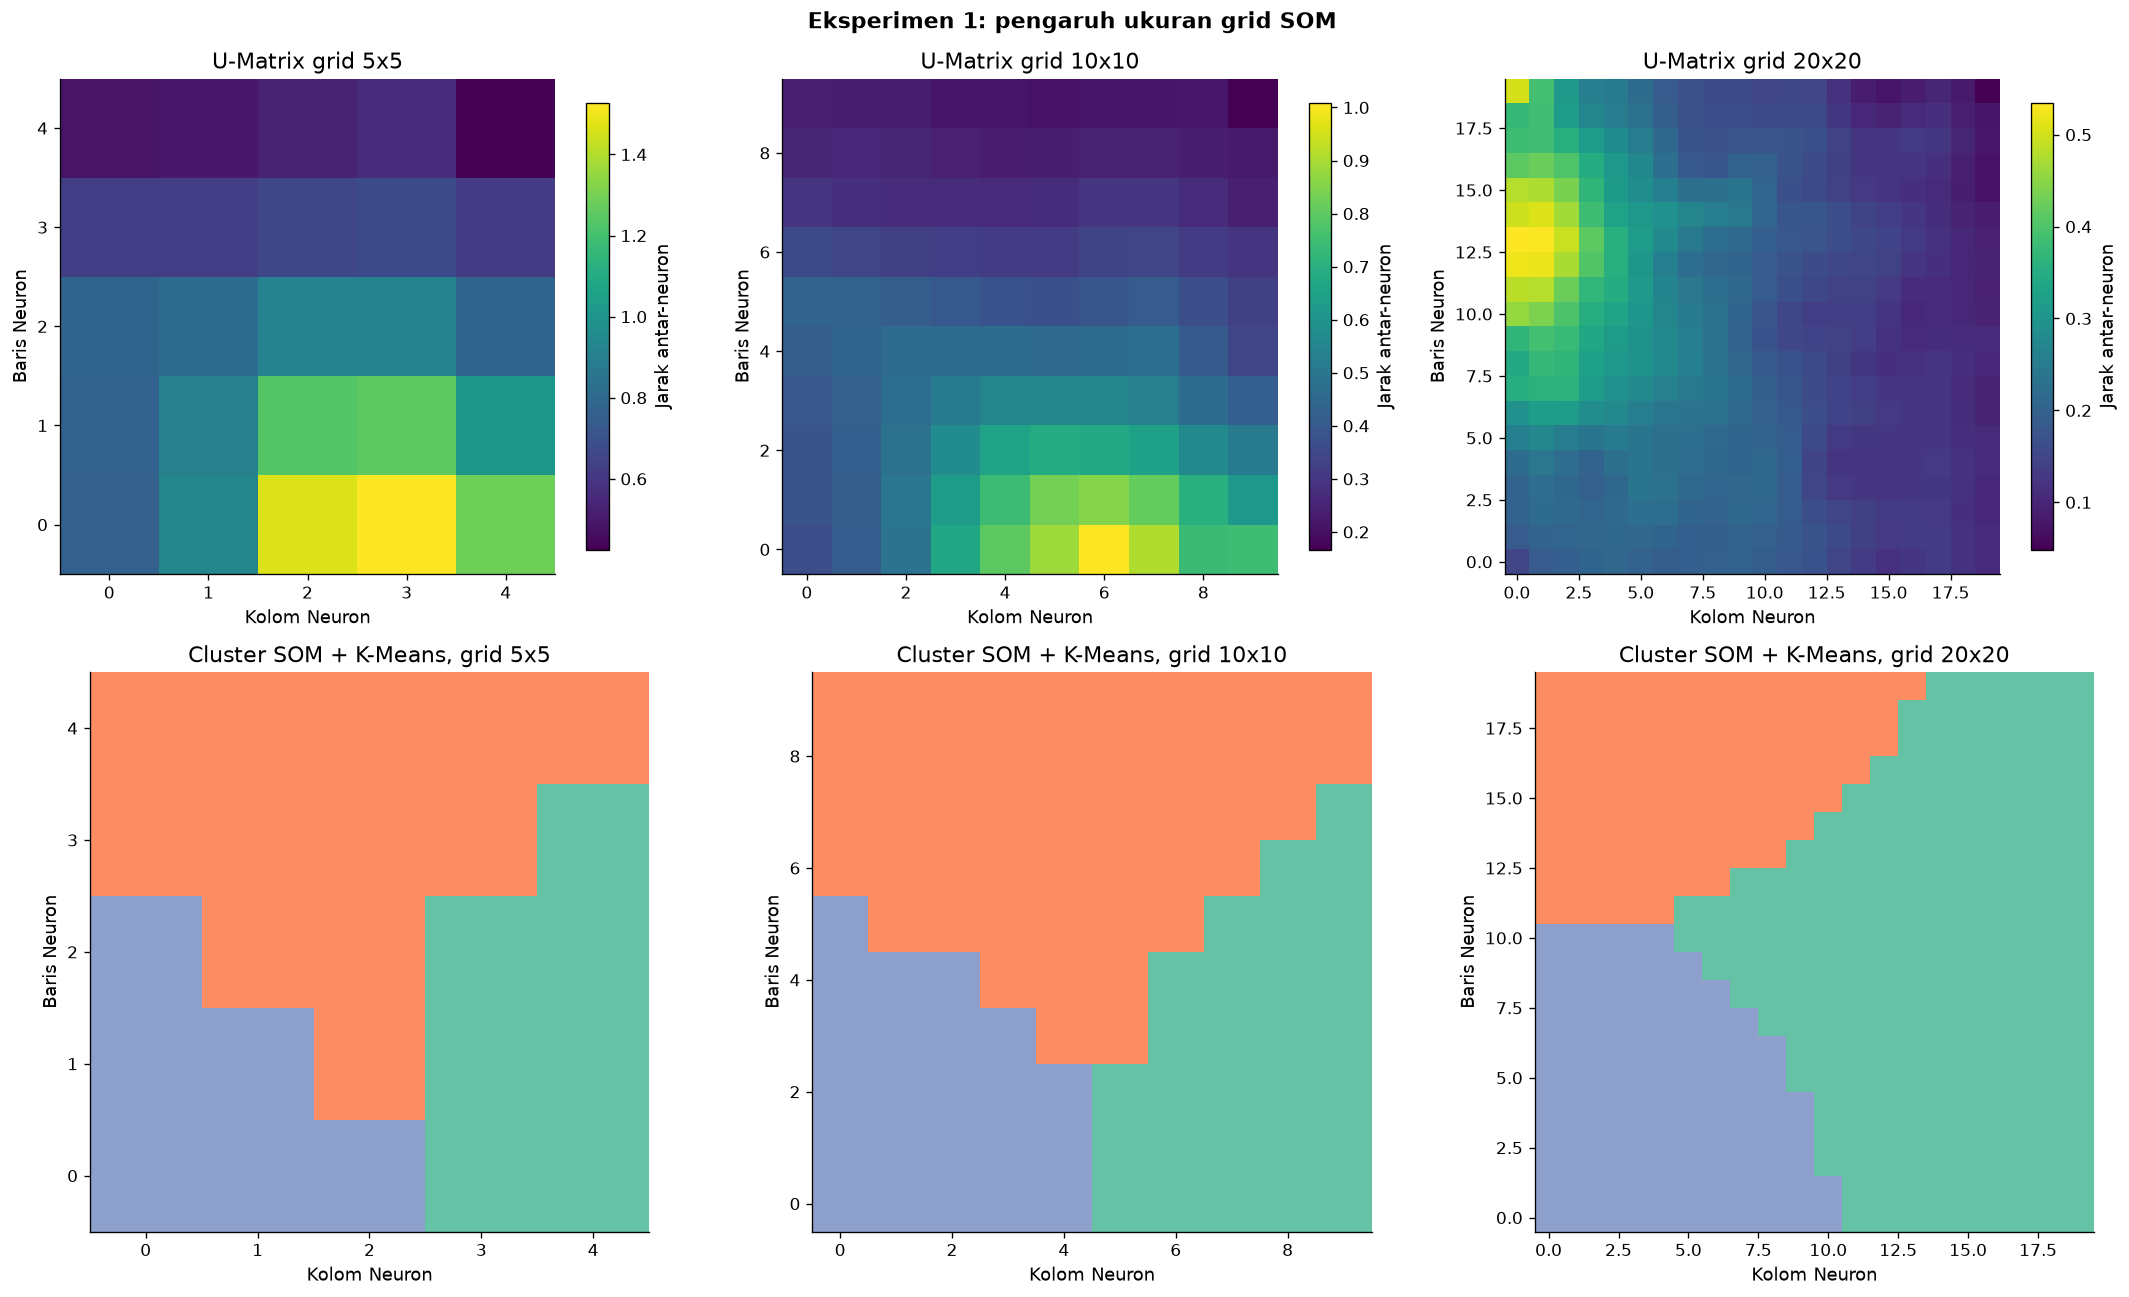

In [38]:
# U-Matrix dan peta cluster untuk tiap ukuran grid (seed = 1)
fig, ax = plt.subplots(2, 3, figsize=(18, 11))
for j, (nb, nk) in enumerate(ukuran_grid):
    s, bmu, npak, lneu, ldat = hasil_grid[(nb, nk)]
    u = hitung_u_matrix(s)
    im = ax[0, j].imshow(u, cmap='viridis', origin='lower', interpolation='nearest')
    plt.colorbar(im, ax=ax[0, j], shrink=0.8, label='Jarak antar-neuron')
    ax[0, j].set_title(f'U-Matrix grid {nb}x{nk}')

    peta_c = np.full((nb, nk), np.nan)
    for p, c in zip(npak, lneu):
        peta_c[p[0], p[1]] = c
    cmap_c = ListedColormap(warna3)
    norm_c = BoundaryNorm(np.arange(-0.5, 3.5, 1), cmap_c.N)
    ax[1, j].imshow(peta_c, cmap=cmap_c, norm=norm_c, origin='lower', interpolation='nearest')
    ax[1, j].set_title(f'Cluster SOM + K-Means, grid {nb}x{nk}')
    for a in (ax[0, j], ax[1, j]):
        a.set_xlabel('Kolom Neuron'); a.set_ylabel('Baris Neuron')
fig.suptitle('Eksperimen 1: pengaruh ukuran grid SOM', fontweight='bold')
plt.tight_layout()
plt.show()

**Pembahasan peta.**

- **U-Matrix:** skala jarak antar-neuron mengecil saat grid diperbesar (maksimum ±1,5 pada 5×5, ±1,0 pada 10×10, ±0,54 pada 20×20), karena neuron bertetangga makin rapat. Pada grid 5×5 U-Matrix hanya menampilkan gradien kasar. Pada 20×20 tampak punggung jarak tinggi di sisi kiri, yaitu wilayah ekor sebaran yang jarang data.
- **Peta cluster:** pada ketiga ukuran grid terbentuk tiga wilayah bersambung dengan susunan relatif yang serupa. Pada grid kecil batas cluster berbentuk blok kasar, sedangkan pada grid besar batasnya lebih halus. Orientasi peta berbeda antar-grid karena orientasi SOM bergantung pada inisialisasi acak (rotasi atau pencerminan), dan nomor atau warna cluster bersifat arbitrer. Karena itu yang dibandingkan adalah pola wilayah, bukan warna.

**Ringkasan:** grid yang lebih besar memberi representasi lebih teliti dan hasil yang lebih stabil, tetapi di atas 10×10 peningkatan kualitas cluster hampir tidak ada, sementara waktu komputasi naik. Untuk 3.537 pelanggan, grid 10×10 sudah memadai untuk clustering, sedangkan 20×20 berguna bila peta ingin dipakai untuk eksplorasi yang lebih rinci.

## Eksperimen 2: jumlah cluster K


,K,Silhouette SOM+KM,DBI SOM+KM,Silhouette KM,DBI KM,Ukuran SOM+KM,Ukuran KM
0,2,0.4503,0.8565,0.4629,0.8210,"[2350, 1187]","[2468, 1069]"
1,3,0.4968,0.6793,0.5006,0.6739,"[1776, 835, 926]","[1830, 815, 892]"
2,4,0.4458,0.7300,0.4621,0.7202,"[1262, 598, 861, 816]","[1345, 483, 842, 867]"
3,5,0.4153,0.8226,0.4173,0.8029,"[1131, 545, 513, 769, 579]","[1049, 297, 838, 839, 514]"
4,6,0.4227,0.7428,0.4181,0.8072,"[180, 576, 451, 699, 513, 1118]","[1057, 286, 699, 762, 454, 279]"


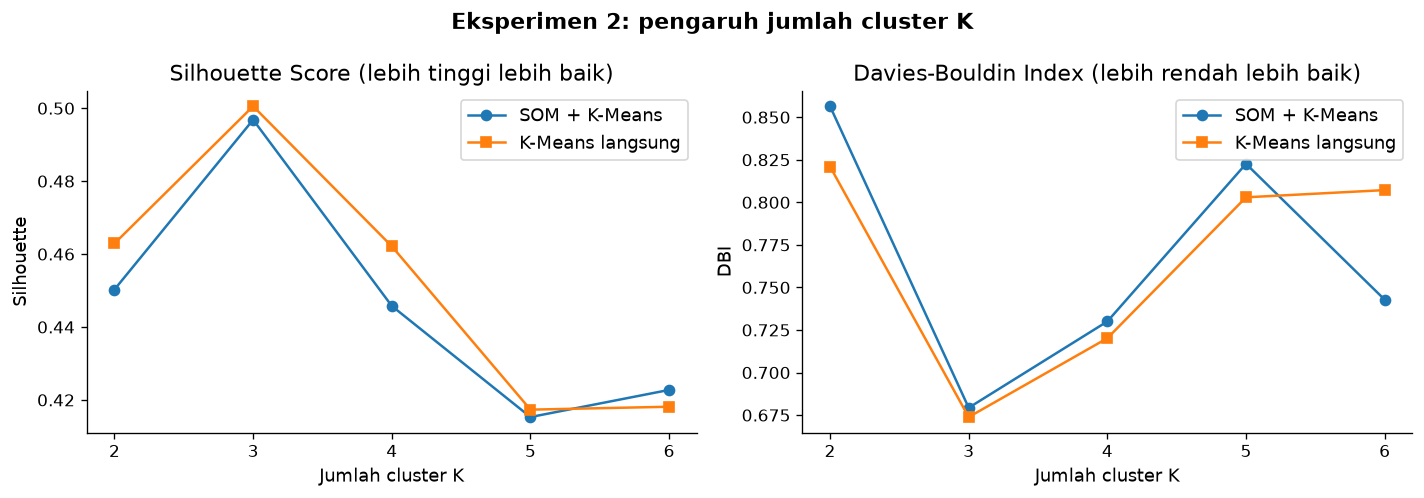

In [39]:
# Eks 2
baris_k = []
for kk in range(2, 7):
    lab_neuron = KMeans(n_clusters=kk, random_state=CFG.SEED).fit_predict(prototipe)
    peta_k = {tuple(p): c for p, c in zip(neuron_criteria, lab_neuron)}
    lab_som = np.array([peta_k[tuple(p)] for p in hasil_pemenang])
    lab_km = KMeans(n_clusters=kk, random_state=CFG.SEED).fit_predict(X_som)
    baris_k.append({'K': kk,
                    'Silhouette SOM+KM': silhouette_score(X_som, lab_som), 'DBI SOM+KM': davies_bouldin_score(X_som, lab_som),
                    'Silhouette KM': silhouette_score(X_som, lab_km), 'DBI KM': davies_bouldin_score(X_som, lab_km),
                    'Ukuran SOM+KM': np.bincount(lab_som).tolist(), 'Ukuran KM': np.bincount(lab_km).tolist()})
hasil_eks2 = pd.DataFrame(baris_k)
display(hasil_eks2.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(hasil_eks2['K'], hasil_eks2['Silhouette SOM+KM'], marker='o', label='SOM + K-Means')
ax[0].plot(hasil_eks2['K'], hasil_eks2['Silhouette KM'], marker='s', label='K-Means langsung')
ax[0].set_title('Silhouette Score (lebih tinggi lebih baik)'); ax[0].set_ylabel('Silhouette')
ax[1].plot(hasil_eks2['K'], hasil_eks2['DBI SOM+KM'], marker='o', label='SOM + K-Means')
ax[1].plot(hasil_eks2['K'], hasil_eks2['DBI KM'], marker='s', label='K-Means langsung')
ax[1].set_title('Davies-Bouldin Index (lebih rendah lebih baik)'); ax[1].set_ylabel('DBI')
for a in ax:
    a.set_xlabel('Jumlah cluster K'); a.set_xticks(range(2, 7)); a.legend()
fig.suptitle('Eksperimen 2: pengaruh jumlah cluster K', fontweight='bold')
plt.tight_layout()
plt.show()

**Pembahasan.**

- **K = 3 terbaik pada kedua pendekatan dan kedua metrik** (SOM + K-Means: Silhouette 0,4968, DBI 0,6793; K-Means langsung: 0,5006 dan 0,6739). Ini mendukung pemilihan K = 3 sebelumnya (pada ruang prototipe: Silhouette 0,4596, DBI 0,7397).
- K = 2 menyatukan segmen berbeda (Silhouette turun ke 0,450 dan 0,463), sedangkan K ≥ 4 memecah kontinum menjadi bagian-bagian yang lebih sulit dibedakan (Silhouette 0,415–0,462 pada K = 4–6, semuanya di bawah K = 3).
- Perbandingan kedua pendekatan: K-Means langsung sedikit lebih baik pada K = 2–5 (selisih Silhouette 0,002–0,017), sedangkan SOM + K-Means lebih baik pada K = 6 (Silhouette 0,4227 vs 0,4181; DBI 0,7428 vs 0,8072). Selisihnya kecil dan tidak konsisten ke satu arah.
- Ukuran cluster: pada K = 2–5, cluster terkecil SOM + K-Means lebih besar (mis. K = 5: 513 vs 297 pelanggan), jadi pembagiannya sedikit lebih seimbang. Pada K = 6 kebalikannya (180 vs 279).

# Pertanyaan Analisis

**1. Mengapa fitur perlu distandardisasi sebelum SOM dan K-Means?**

SOM dan K-Means memakai jarak Euclidean (mencari BMU, memperbarui bobot, dan menugaskan titik ke centroid), sehingga fitur berskala besar mendominasi. Setelah penanganan outlier, Recency berkisar 0–331 (simpangan baku 91), Frequency 1–233 (simpangan baku 47), dan Monetary 0–£3.004 (simpangan baku 682). Tanpa standardisasi, Monetary menyumbang sekitar 98% total varians sehingga hampir seluruh jarak ditentukan oleh Monetary saja, sedangkan Recency dan Frequency diabaikan. Standardisasi z-score ($z=(x-\mu)/\sigma$) membuat setiap fitur bermean 0 dan simpangan baku 1 sehingga berkontribusi seimbang. Standardisasi juga membuat parameter SOM (α, σ, inisialisasi bobot) bekerja pada skala yang sebanding untuk semua fitur.

**2. Apa itu BMU, dan bagaimana BMU dipakai untuk memberi label cluster?**

BMU (*Best Matching Unit*) adalah neuron yang vektor bobotnya paling dekat dengan suatu observasi. Pada notebook ini BMU dicari dengan `SOM.pemenang(X)` dan menghasilkan pasangan (baris, kolom) untuk tiap pelanggan. Pelabelan dilakukan dalam tiga langkah. Pertama, bobot dari 400 neuron yang menjadi BMU bagi minimal satu pelanggan diambil sebagai prototipe. Kedua, K-Means (K = 3) mengelompokkan prototipe tersebut sehingga tiap neuron memperoleh label cluster. Ketiga, setiap pelanggan mewarisi label dari neuron BMU-nya (`mapping_label`). Akibatnya semua pelanggan dengan BMU yang sama otomatis berada pada cluster yang sama.

**3. Apa pengaruh ukuran grid SOM terhadap representasi pola data?**

Berdasarkan Eksperimen 1, grid yang lebih besar merepresentasikan data lebih teliti: QE turun dari 0,259 (5×5) ke 0,130 (10×10) dan 0,071 (20×20), dan U-Matrix menampilkan detail yang lebih halus (misalnya wilayah ekor sebaran pada 20×20). Grid kecil memaksa tiap neuron mewakili sekitar 141 pelanggan yang berbeda, sehingga batas cluster kasar dan hasil kurang stabil antar-seed (simpangan baku Silhouette 0,0071). Grid besar memberi sedikit pelanggan per neuron (±9) dan lebih lambat dihitung. Pada dataset ini kualitas cluster mulai jenuh pada 10×10, sehingga grid lebih besar terutama menambah detail visualisasi.



Eksperimen pendukung untuk Pertanyaan 4 (sel di bawah): K-Means diterapkan pada **koordinat baris-kolom** neuron, lalu hasilnya dibandingkan dengan K-Means pada **vektor bobot** neuron.


In [40]:
# Ilustrasi Pertanyaan 4: K-Means pada koordinat baris-kolom grid vs pada bobot neuron
koordinat = neuron_criteria.astype(float)          # (baris, kolom) tiap neuron terpakai
label_koordinat = KMeans(n_clusters=3, random_state=CFG.SEED).fit_predict(koordinat)
peta_koord = {tuple(p): c for p, c in zip(neuron_criteria, label_koordinat)}
label_data_koord = np.array([peta_koord[tuple(p)] for p in hasil_pemenang])

pembanding = pd.DataFrame({'Silhouette (PCA 2D)': [silhouette_score(X_som, hasil_pemenang_cluster), silhouette_score(X_som, label_data_koord)],
                           'DBI (PCA 2D)': [davies_bouldin_score(X_som, hasil_pemenang_cluster), davies_bouldin_score(X_som, label_data_koord)],
                           'ARI vs SOM+KM bobot': [1.0, adjusted_rand_score(hasil_pemenang_cluster, label_data_koord)]}, index=['K-Means pada bobot neuron', 'K-Means pada koordinat grid'])
display(pembanding.round(4))

,Silhouette (PCA 2D),DBI (PCA 2D),ARI vs SOM+KM bobot
K-Means pada bobot neuron,0.4968,0.6793,1.000
K-Means pada koordinat grid,0.4181,0.7405,0.509


**4. Mengapa K-Means diterapkan pada bobot neuron, bukan pada koordinat baris-kolom grid?**

Koordinat baris-kolom hanya menyatakan *letak* neuron pada peta, bukan nilai fitur pelanggan. Jarak pada grid tidak sama dengan kemiripan data: U-Matrix menunjukkan jarak rata-rata bobot ke neuron tetangga bervariasi sekitar 11 kali lipat (0,048–0,535), sehingga dua neuron yang bersebelahan bisa saja sangat berbeda, dan dua neuron berjauhan bisa mirip. K-Means pada koordinat hanya akan memotong grid menjadi blok-blok geometris tanpa memperhatikan data. Vektor bobot berada di ruang fitur yang sama dengan data dan merupakan ringkasan (prototipe) dari pelanggan yang dipetakan ke neuron tersebut, sehingga pengelompokan bobot mencerminkan kemiripan perilaku RFM. Hasil sel di atas mendukung hal ini: K-Means pada koordinat grid memberi Silhouette 0,4181 dan DBI 0,7405 (lebih buruk dari 0,4968 dan 0,6793 pada bobot), dan labelnya hanya cocok sebagian dengan pengelompokan bobot (ARI = 0,509). Selain itu, K-Means pada bobot hanya memproses paling banyak 400 prototipe, bukan 3.537 pelanggan.

**5. Apakah SOM + K-Means selalu menghasilkan clustering yang lebih baik daripada K-Means langsung?**

Tidak. Pada K = 3, K-Means langsung sedikit lebih baik (Silhouette 0,5006 vs 0,4968; DBI 0,6739 vs 0,6793), dan hasil ini konsisten pada lima seed (Silhouette 0,5005 ± 0,0001 untuk K-Means langsung vs 0,4971 ± 0,0007 untuk SOM 20×20) serta pada ruang RFM 3D. Pada Eksperimen 1, DBI grid 10×10 sedikit lebih rendah daripada K-Means langsung, tetapi selisihnya masih dalam rentang variasi antar-seed. Pada Eksperimen 2, SOM + K-Means hanya unggul pada K = 6 dan kalah pada K = 2–5. Pembagian pelanggan kedua pendekatan hampir identik (ARI = 0,9421; 98,11% label sama). Jadi SOM tidak menjamin cluster yang lebih baik, dan pada dataset ini manfaatnya terletak pada visualisasi serta interpretasi struktur data, bukan pada kenaikan metrik.


# Keterbatasan Pendekatan

1. **Satu dataset dan fitur sedikit.** Hanya tiga fitur RFM yang direduksi ke 2 komponen PCA (±88,2% varians), sehingga ±11,8% informasi hilang dan keunggulan SOM pada data berdimensi tinggi tidak teruji.
2. **Metrik internal.** Silhouette dan DBI cenderung menguntungkan cluster kompak dan cembung, geometri yang sama dengan yang dioptimalkan K-Means. Tidak ada label sebenarnya, sehingga validitas segmen perlu dinilai juga secara bisnis.
3. **Penanganan data.** Nilai negatif pada `Quantity` (10.624 baris, sebagian besar pembatalan faktur berawalan 'C') dan `UnitPrice` diubah dengan `abs()`, sehingga pembatalan ikut dihitung sebagai pembelian dan dapat menaikkan Monetary. Duplikat (5.268 baris) tidak dibuang. Baris tanpa `CustomerID` (135.080 baris atau 24,93%) dibuang, sehingga pembeli tanpa akun tidak tercakup. *Frequency* dihitung dari jumlah baris item, bukan faktur unik, sehingga mencerminkan banyaknya item, bukan banyaknya kunjungan.
4. **Penghapusan outlier.** Pembuangan outlier dengan IQR menghapus 835 dari 4.372 pelanggan (19,1%), termasuk pelanggan bernilai paling tinggi (mis. pedagang grosir). Segmen "Bernilai Tinggi" di sini bersifat relatif terhadap pelanggan yang tersisa, dan pelanggan ekstrem sebaiknya dianalisis terpisah.
5. **Ketergantungan pada inisialisasi dan implementasi.** Hasil SOM bergantung pada seed (diperiksa dengan 5 seed pada Eksperimen 1). SOM ditulis sendiri dengan pelatihan *online* sehingga lebih lambat dan belum dibandingkan dengan pustaka seperti MiniSom.
6. **Data historis.** Segmen berasal dari transaksi Desember 2010–Desember 2011 dan perlu diperbarui bila perilaku pelanggan berubah.


# Kesimpulan

1. SOM 20×20 berhasil memetakan 3.537 pelanggan ke grid dua dimensi yang tersusun teratur: Recency tinggi di kiri-bawah serta Frequency dan Monetary tinggi di kiri-atas. Pelanggan yang berdekatan pada peta memiliki pola RFM yang mirip.
2. SOM + K-Means (K = 3) menghasilkan tiga segmen yang dapat ditafsirkan: Aktif Menengah (50,2%), Bernilai Tinggi (23,6%), dan Tidak Aktif (26,2%).
3. K-Means langsung memberi hasil yang hampir identik (ARI = 0,9421) dan sedikit lebih baik secara metrik (Silhouette 0,5006 vs 0,4968; DBI 0,6739 vs 0,6793). Selisihnya sangat kecil.
4. Eksperimen: grid lebih besar menurunkan *quantization error* dan menstabilkan hasil, tetapi kualitas cluster hampir jenuh pada 10×10. K = 3 terbaik untuk kedua pendekatan.
5. Pada dataset ini SOM bermanfaat sebagai alat eksplorasi dan visualisasi, bukan sebagai penghasil cluster yang lebih baik secara kuantitatif.


# Daftar Pustaka

**Dataset**

- Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
- Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management, 19*(3), 197–208. https://doi.org/10.1057/dbm.2012.17

**Literatur**

- Agus, I., & Hasibuan, M. S. (2025). Customer segmentation using an enhanced RFM–K-Means framework on the Online Retail dataset. *International Journal of Informatics and Information Systems, 8*(4), 221–233. https://doi.org/10.47738/ijiis.v8i4.289
- Khanfar, I., Khanfar, I., & Odeh, M. (2024). Customer segmentation based on RFM attributes using machine learning. In *Intelligent Systems, Business, and Innovation Research* (Studies in Systems, Decision and Control, Vol. 489, pp. 369–386). Springer. https://doi.org/10.1007/978-3-031-36895-0_30
- Liao, J., Jantan, A., Ruan, Y., & Zhou, C. (2022). Multi-behavior RFM model based on improved SOM neural network algorithm for customer segmentation. *IEEE Access, 10*, 122501–122512.
- Winaryanti, H. S., Hadi, H. P., & Rachmawanto, E. H. (2024). Customer segmentation using K-Means clustering with RFM method (Case study: PT. Dewangga Travindo Semarang). *Journal of Applied Intelligent System, 9*(1), 147–160. https://doi.org/10.62411/jais.v9i1.10440
- Yunita, I., Ali, P. R., Kartawidjaja, M. A., & Sukwadi, R. (2025). Segmentasi pelanggan menggunakan K-Means clustering: Menganalisis metrik RFM untuk strategi pemasaran. *Jurnal Media Teknik dan Sistem Industri, 9*(1), 58–66. https://doi.org/10.35194/jmtsi.v9i1.4452
- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
